# Final Project: OHIE Medicaid Policy Simulation
---

**Project Name:** Allocating Scarce Medicaid Coverage: A Counterfactual Comparison of Lottery, Need-Based, and Learned Targeting in the Oregon Health Insurance Experiment

**Author:** Chayce Reed

**Date:** 10/12/26

<br>

**Note:** This notebook is a work in progress for the final project, and is actively being worked on. Supervised machine learning models, causal inference methods, and visualizations are still being added, updated, and finalized.

<br>

### Data Source
---

**Data Source:** Oregon Health Insurance Experiment (OHIE) Public Use Dataset

**Data Access:** https://www.nber.org/research/data/oregon-health-insurance-experiment-data (Free registration, if prompted)

**Data Description:** "In 2008, a group of uninsured low-income adults in Oregon was selected by lottery to be given the chance
to apply for Medicaid. This lottery provides a unique opportunity to gauge the effects of expanding access
to public health insurance on the health care use, financial strain, and health of low-income adults using a
randomized controlled design. The Oregon Health Insurance Experiment followed and compared those
selected in the lottery (treatments) with those not selected (controls)."

**Data Files:** The dataset includes six separate datasets from the OHIE that have been made pubiicly available. For this project, the following datasets will be used: Descriptive Variables (oregonhie_descriptive_vars.dta), State Program Variables (oregonhie_stateprograms_vars.dta), and Tweleve Month Mail Survey (oregonhie_survey12m_vars.dta).

**Data Selection:** The OHIE dataset was selected for this project because it provides a unique opportunity to analyze the effects of Medicaid coverage on low-income adults in Oregon. The experiment's randomized "lottery" design allows for the comparison between those who were selected for Medicaid coverage and those who were not, making it a useful dataset for studying the impact of health insurance on various outcomes. This dataset also lines up directly with my research interests and goals. I am applying to PhD programs to study causal inference for health services, policy, and equity research, across two key areas: how health policy and health care delivery systems shape access for marginalized populations, and how automated decision-making produces and entrenches disparities in health care. This dataset and project fits squarely into the former, and will allow me to investigate how coverage decisions affect low-income, uninsured populations and how those decisions could be made more equitably. The data includes characteristics recorded before the lottery, which makes it possible to estimate the causal effect of a coverage offer, test whether the effect differs across subgroups, and simulate whether an alternative allocation rule (e.g., need-based, learned-targeting) would have prevented more medical debt than the lottery. This combination of causal inference, policy simulation, and equity analysis is the kind of work I am hoping to develop my future PhD research agenda around, which makes it a very exciting dataset and project to work on.

**Binary Classification:** Yes. The target whether the respondent owes money for medical expenses at 12 months (binary: 1 = yes, 0 = no).

**Observation Count:** 23,741 respondents to the 12-month survey, out of 74,922 total people on the original lottery list.

**Predictor Variable Count:** 15 predictor variables measured before the lottery, including: age, sex, english-language preference, self-signup, phone number provided, PO box addressed used, metro-area zip, signup week, first-day signup, last-day signup, prior SNAP participant, prior TANF participant, household SNAP dollars, household TANF dollars, and any-state program indicator.

**Acknowledgements:** The project uses the public-use data from the Oregon Health Insurance Experiment, made available by the National Bureau of Economic Research (NBER). Finkelstein, Amy. Oregon Health Insurance Experiment Public Use Data, 2013. Available at https://www.nber.org/research/data/oregon-health-insurance-experiment-data.

<br>

### Data Quality Assessment
---

**Anticipated Preprocssing Steps:**

- Merge the three datasets (descriptive, state program, and 12-month survey) into a single dataset for analysis.
- Convert columns that loaded as an object datat type to the appropriate data type (e.g., categorical, numeric).
- Rename variables to shorter, more interpretable names.
- Restrict dataset to only include respondents who completed the 12-month survey.
- Derive age from birth year and survey date.
- Review data dictionary to verify if missing SNAP/TANF benefit dollar amounts should be set to 0 or treated as missing.
- Standardize continuous predictors (if appropriate, pending modeling approach, TBD).
- Apply survey weights (per the data dictionary and documentation) to ensure that the analysis is properly representative of the true population

**Potential Challenges with the Dataset:**

- Offers vs coverage: Winning the lottery gave people the chance to apply for Medicaid coverage, but doesnt guarentee they were enrolled. This means that the treatment group (selected in the lottery) may include people who were not actually covered by Medicaid. To address this challenge, we will conduct the primary analysis using intention-to-treat, with an additional secondary analysis for those who were actually enrolled in Medicaid coverage.
- Survey non-response: Only 23,741 of the 74,922 people on the original lottery list completed the 12-month survey. Respondents may differ systematically from non-respondents, which could bias the results. To address this challenge, we will apply survey weights per the documentation to help ensure the analysis is properly representative of the true population.
- Skewed SNAP/TANF benefit dollar amounts: Based on the data exploration and visualization, the SNAP and TANF benefit dollar amounts appeared to be highly skewed, with small number of respondents having very high amounts.
- 2008 Oregon Data: The data is from a 2008 Oregon-specific experiment, meaning that the results may not be generalizable to other states or time periods. Therefore, the findings should be framed carefully and not overstate modern implications.

<br>

### Project Plan
---

**Target Variable:**

- The primary outcome variable is cost_any_owe_12m, defined as "Currently owe money for medical expenses" at the 12 month follow-up survey (binary: 1 = yes, 0 = no).
- Additional secondary outcomes include cost_borrow_12m, cost_refused_12m, and cost_any_oop_12m, which represent "Borrowed money/skipped bills to pay health care bills in last 6 months?", "Have you been refused care because you owed money for a past treatment?", "Any out of pocket costs for medical care in the past 6 months", respectively.
- Based on the analysis below, approximately 55% of all respondents reported having medical debt, 34% reported borrowing money or skipping bills to pay health care bills, 7% reported being refused care due to medical debt, and 52% reported out of pocket costs for medical care in the last 6 months. These variables will be used to evaluate the impact of Medicaid coverage on financial strain related to medical expenses.

**Prediction Problem:**

- Binary classification: predict whether a low-income, uninsured adult will owe money for medical expenses 12 months after applying for Medicaid, and which variables are the most predictive of that outcome.
- Inputs are characteristics recorded at signup (e.g., age, sex, language preference, prior state program participation, etc), plus whether the person was selected in the lottery.
- This prediction problem and classifier is not the ultimate end goal, and it will feed into the causal analysis and policy simulation later on.
- Model Selection: Logistic regression, random forest, and XGBoost, and selecting the best performing, based on Brier score, as the final model.

**Evaluation Metrics:**

- AUC: For how well each model discriminates between those who owe money for medical expenses and those who do not.
- Brier Score: For how well each model predicts the probability of owing money for medical expenses.
- Calibration curves: For how closely predicted probabilities match observed outcome rates.
- Replication of Original Study: Ensure the causal analysis reproduces the same (or similar) results as the original study, before proceeding with the prediction model, counterfactual simulation, or subgroup analysis.
- Test Causal Methods Simulation against Simulated Dataset (TBD, if time permits): Build a test dataset with known truth, and run through the analysis pipeline to confirm the results are accurate.

**Causal Inference**

- Estimate the effect of being offered Medicaid on medical debt, with the lottery being the source of random assignment.
- Estimate the effect of actually enrolling.
- Check whether the effects differ across subgroups (e.g., age, sex, language preferance, prior SNAP/TANF participation)

**Policy Simulation**

- Ask what the total medical debt would have been if the same number of coverage offers had been allocated based on need (e.g., prior SNAP/TANF participation), instead of a lottery.
- Ask what the total medical debt would have been if everyone on the list had recieved a coverage offer, inestad of a lottery.
- Ask what the total medical debt would have been if the same number of coverage offers had been allocated based on the largest predicted benefit, instead of a lottery. (TBD, if time permits).
- Conduct a subgroup analysis to see which groups are most impacted by the allocation rule change.

<br>

### Analysis Pipeline Enhancements
---

1. First, I built the cross-validation folds once with GroupKFold on household ID and reused them for classifier tuning, out-of-fold predictions, the cross-fitted outcome models in g-computation and AIPW. Household members share an address, income, and lottery selection status, so a random split would put near-copies of test cases in training, potentially inflating performance. One set of folds also makes every out-of-sample number in the notebook comparable.

2. Second, I used Spearman correlation matrix to revise the predictor set before modeling. any_program_pre correlated 0.999 with snap_pre, so I dropped it from the model features while keeping it for the descriptive subgroup plots.

3. Third, I stored the three classifiers into a single classification_models dictionary, so that I could loop over the dictionary and rerun every model in a single step. This dictionary is then reused for out-of-fold predictions, the performance metrics table, the overfit check, ROC and calibration curves, confusion matrices, and permutation importance. The out-of-fold loop also saves each fold's fitted model for reuse in the policy simulation. This also makes it so that adding or swapping a classifier means updating one dictionary entry, rather than each independent code block.

4. Fourth, I replaced the automatic threshold with a documented choice, based on a defined priority metric (recall). F1-maximization labeled nearly everyone as having medical debt, and Youden's J weights both errors equally, so instead, the threshold was selected from a sensitivity / specificity sweep with recall (sensitivity) selected as the primary metric.

5. Fifth, I added an evaluation table and overfit check. The metric table reports AUC, sensitivity, specificity, accuracy, precision, recall, F1, Brier score, alongside ROC curve and calibration curve plots. Additionally, an overfit check is conducted that refits each model on the full fit sample and compares train AUC and Brier score against the out-of-fold values, so any overfitting or major difference between in-sample and out-of-sample performance is identified. This also helps to identify if the weak discrimination performance due to the model, or a result of the features not being very informative of the outcome.

6. Sixth, I added three plots of what drives predictions (logistic regression coefficient plot, permutation importance plots, and SHAP plot). The standardized logistic coefficients give the direction and magnitude on a common scale (for comparability), colored by direction. Permutation importance is computed for all three models with Brier score as the loss, measuring how much prediction degrades when each feature is shuffled, allowing us to compare what features each model learns from. Finally, SHAP values for XGBoost decompose each individual prediction into per-feature contributions, and plotted using a beeswarm plot.

7. Seventh, I added a covariate balance check before estimating any treatment effect. Each pre-lottery covariate is regressed on the treatment indicator with the design fixed effects, survey weights, and household-clustered standard errors, with the results are collected into a table to compare means between the control and treatment groups, along with their p-value. This check allows us to confirm that the randomized "lottery" design of the experiment properly balanced the covariates, providing additional justification that the results can be read as causal.

8. Eighth, I implemented four estimators and organized them by what they estimate. The intent-to-treat (ITT) of a lottery offer is estimated three ways: weighted OLS with design fixed effects, g-computation, and AIPW. The local average treatment effect (LATE) is estimated by 2SLS with the lottery as the instrument. All four estimators loop over the same four outcomes, handling missingness per outcome to ensure maximal sample size per outcome. This approach also enables looping through and creating tables, allowing us to compare results across methods and outcomes.

9. Ninth, I tuned both tree models (random forest and XGBoost) with RandomizedSearchCV over a predfined hyperparameter grid. The search is scored on the Brier score rather than accuracy or AUC, since Brier more appropriately rewards well-calibrated models and probabilities. The household-grouped folds are passed as the cv argument, so that tuning never evaluates a candidate on the same household it was trained on. The best parameters and cross-validated Brier score are then printed for each model and the selected estimators are stored in the classification_models dictionary so that the tuned versions are carried through and reused throughout the rest of the notebook.

<br>

### Notebook Structure
---

- **1. Setup**
  - 1.1. Package Version Check & Installation
  - 1.2. Package Importing & Seed Setting
  - 1.3. File Path Creation & Locating Data
- **2. Data Loading & Merging**
  - 2.1. Data Loading
  - 2.2. Data Subsetting & Merging
  - 2.3. Variable Renaming & Labeling
  - 2.4. Derived Variables
  - 2.5. Data Subsetting & Variable Grouping
- **3. Data Structure & Loading**
  - 3.1. Data Structure, Type, & View
- **4. Data Checks & Cleaning**
  - 4.1. Data Checks Functions
  - 4.2. Data Checks
  - 4.3. Data Cleaning
- **5. Data Exploration & Visualization**
  - 5.1. Summary & Visualization Functions
  - 5.2. Descriptive Statistics
  - 5.3. Treatment Group Comparisons
  - 5.4. Distribution Visualizations
  - 5.5. Outcomes by Treatment Groups
  - 5.6. Subgroup Analysis
  - 5.7. Predictor Correlation Matrix & Heatmap
- **6. Supervised Machine Learning Classification**
  - 6.1. Design Matrix & Cross-Validation Folds
  - 6.2. Logistic Regression
  - 6.3. Random Forest
  - 6.4. XGBoost
  - 6.5. Out-of-Fold Predictions
  - 6.6. Threshold Selection
  - 6.7. Performance Metrics & Overfit Check
  - 6.8. ROC & Calibration Curves
  - 6.9. Confusion Matrices
  - 6.10. Variable Importance
- **7. Causal Inference**
  - 7.1. Propensity Score Stratum & Survey Weights
  - 7.2. Covariate Balance Check
  - 7.3. Intention-to-Treat (ITT): OLS
  - 7.4. Local Average Treatment Effect (LATE): 2SLS
  - 7.5. G-Computation
  - 7.6. AIPW
  - 7.7. Summary of Causal Estimates
- **8. Heterogeneity & Subgroup Analysis**
  - 8.1. Causal Forest
  - 8.2. CATE Distribution
  - 8.3. Calibration Test & GATES
  - 8.4. Subgroups Analysis: Age Group, Sex, Language, Prior SNAP/TANF
  - 8.5. Forest Feature Importance
  - 8.6. Summary of Causal Forest & Subgroup Analysis
- **9. Policy Simulation**
  - 9.1. Determine Fixed Budget
  - 9.2. Allocation Rules: Lottery, Need-Based, Risk-Based, Universal
  - 9.3. Doubly Robust Evaluation of Each Rule using AIPW
  - 9.4. G-Computation Cross-Check
  - 9.5. Household Bootstrap for Uncertainty Estimation
  - 9.6. Budget Sweep & Summary 
- **10. Summary & Limitations**
  - 10.1. Results
  - 10.2. Limitations
  - 10.3. Conclusions

<br>

### How To Run
---

1. Open the notebook in Google Colab.
2. Download the OHIE public-use data from NBER: https://www.nber.org/research/data/oregon-health-insurance-experiment-data. Registration is free. The file is `oregon_puf.zip`.
3. Run the notebook using `Run all`. The setup step will automatically install required packages. When the data location step runs, a "Choose Files" button appears below the cell; click it and select `oregon_puf.zip`. Alternatively, drag the zip into the Files panel (folder icon, left sidebar) before running, and the notebook will find automatically. The notebook will unzip the zip file and locate the appropriate `.dta` files automatically.

<br>

Note: When running this notebook in Google Colab, the random forest and XGBoost hyperparameter tuning may take several minutes to complete.

<br>

## 1. Setup

---

This section contains:
- 1.1. Package Version Check & Installation
- 1.2. Package Importing & Seed Setting
- 1.3. File Path Creation & Locating Data


#### 1.1. Package Version Check & Installation

In [2]:
# Load internal python libraries needed for package version checks and installations
import importlib.metadata as md
import platform
import subprocess
import sys

# Python version this notebook was built and tested with
# Unable to change the python runtime version in google colab,
# An idea for the final project is to provide a dockerfile, so that an the full/exact environemnt can be rebuilt and rerun outside of Colab
PYTHON_VERSION = "3.13.15"
# Packages not preinstalled on the Colab environment, which can can specify and install specific versions for on the Colab environment
PACKAGE_VERSION = {
    "pyreadstat": "1.3.6",
    "linearmodels": "7.0",
    "xgboost": "3.4.1",
    "econml": "0.17.0",
    "shap": "0.52.0"
}
# Preintalled packages on the Colab environment already, changing the versions during runtime risks creating downstream issues if versions change
# For full/exact environment, a future idea is to provide a dockerfile for rebuilding and rerunning outside of Colab
PREINSTALLED_PACKAGEs = ["pandas", "numpy", "scipy", "matplotlib", "seaborn", "scikit-learn", "statsmodels", "operator", "sklearn"]

# Check current google colab environment python version, and print message to notify user if it is not the same version the notebook was built and tested with
if not platform.python_version().startswith(PYTHON_VERSION):
    print(f"Note: Notebook built and tested on Python {PYTHON_VERSION}, but environment is currently running {platform.python_version()}.")

# Note: For learning how to improve on my previous versions package version installation workflow
  # Claude Fable 5. Based on the response to prompt: "What is the best practice approach for installing specific version of python packages in the Google Colab environment."
# Lets create a function for checking if a package is already installed, and returning the version number if it is
def installed_version(pkg):
    """Check if package is installed.
    If installed, return version number
    If not installed, return None
    """
    try:
        return md.version(pkg)
    except md.PackageNotFoundError:
        return None

# Create a list of packages to install if packages are not already installed or are not the appropriate version
to_install = [f"{p}=={v}" for p, v in PACKAGE_VERSION.items() if installed_version(p) != v]

# Check if any packages need to be installed, if so, install the appropriate version
if to_install:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + to_install, check = True)

Note: Notebook built and tested on Python 3.13.15, but environment is currently running 3.13.5.


#### 1.2. Package Importing & Seed Setting

In [3]:
# Standard python libraries
import zipfile
from pathlib import Path
from operator import lt, le, eq, ge, gt
import copy
import textwrap

# Data handling
import numpy as np
import pandas as pd
import pyreadstat

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Supervised machine learning classification
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, brier_score_loss, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from scipy.special import logit
from xgboost import XGBClassifier
import shap

# Causal inference
import statsmodels.api as sm
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS
from econml.grf import CausalForest


In [4]:
# Set seed for reproducibility
SEED = 123
rng = np.random.default_rng(SEED)

#### 1.3. File Path Creation & Locating Data

In [5]:
# Lets define the filepaths for our raw dataset and outputs
INPUT = Path("data/raw")
OUTPUT = Path("output/figures")

# Now, lets create the directories themselves
INPUT.mkdir(parents = True, exist_ok = True)
OUTPUT.mkdir(parents = True, exist_ok = True)

In [6]:
# Lets create a function to:
#   (1) check if the data exists in the current environment
#   (2) if exists and is a zip, unpack it
#   (3) if exists and is already unpacked, do nothing
#   (4) if it does not exist, prompt user to upload, using google.colab files to display a popup for easy upload
# Note: To learn how to search the Google Colab environment for appropriate files, and if a zip is found, unpack it
  # Claude Fable 5. Based on the response to prompt: "I want to be able to locate if a zip exists anywhere in the current Colab environment, and if so, unpack it.
  # Additionally, if the zip is already unpacked and the dta files already exist, then use those. If no zip or dta files are found, I want to prompt to the user to upload them."
def locate_data():
    """Check for OHIE zip (or extracted .dta files), and prompt if they are not already present"""
    # First, lets check if the dta files are already present (files uploaded and zip already unpacked)
    if list(Path(".").rglob("oregonhie_*.dta")):
      return
    zips = list(Path(".").rglob("*.zip"))
    if zips:
      zipfile.ZipFile(zips[0]).extractall(INPUT)
      return
    # Neither zip nor dta were found, prompt for upload
    # Inlcuding this here allows us to only import the google.colab files package if its actually needed
    from google.colab import files
    # Prompt to the user to upload the zip file
    print("Upload oregon_puf.zip from the NBER page linked above.")
    # Check each uploaded file to see if it is a zip, if so, unpack it
    for name in files.upload():
        if name.endswith(".zip"):
            zipfile.ZipFile(name).extractall(INPUT)

# Run the function above
locate_data()
# Identify all dta files
dta_files = sorted(Path(".").rglob("oregonhie_*.dta"))
# Flag to user if dta files are not found, prompting user to upload the zip file
assert dta_files, "No oregonhie_*.dta files found: upload oregon_puf.zip from the NBER page linked above."
# Once files are uploaded and found, print and display all found data files to user
print("Data files found:", *[f.name for f in dta_files], sep = "\n")

Data files found:
oregonhie_descriptive_vars.dta
oregonhie_ed_vars.dta
oregonhie_inperson_vars.dta
oregonhie_patterns_vars.dta
oregonhie_stateprograms_vars.dta
oregonhie_survey0m_vars.dta
oregonhie_survey12m_vars.dta
oregonhie_survey6m_vars.dta


## 2. Data Loading & Merging

---

This section contains:
- 2.1. Data Loading
- 2.2. Data Subsetting & Merging
- 2.3. Variable Renaming & Labeling
- 2.4. Derived Variables
- 2.5. Data Subsetting & Variable Grouping


#### 2.1. Data Loading

In [7]:
# Lets create a function to read in a dta file and extract the data, labels, and metadata
# Note: To learn how to create a function to read in dta files in Python
  # Claude Fable 5. Based on the response to prompt: "I want to create a reusable function for reading in dta files in Python."
def read(name):
    """Read specified dta file and extract the data, labels, and metadata from it"""
    # Locate specific dta file
    path = next(INPUT.rglob(f"{name}.dta"))
    # Use pyreadstat package to read dta file
    df, meta = pyreadstat.read_dta(str(path), apply_value_formats = False)
    labels = dict(zip(meta.column_names, meta.column_labels))
    # Return data, labels (contains interpretable, readable labels for each variable), and metadata
    return df, labels, meta

# For this analysis, we need three datasets: Descriptive Variables, State Program Variables, and Tweleve Month Mail Survey
descriptive_df, descriptive_lab, descriptive_meta = read("oregonhie_descriptive_vars")
stateprograms_df, stateprograms_lab, stateprograms_meta = read("oregonhie_stateprograms_vars")
survey12m_df, survey12m_lab, survey12m_meta = read("oregonhie_survey12m_vars")

#### 2.2. Data Subsetting & Merging

In [8]:
# Before merging the three datatsets, lets subset each to include only the variables we are interested in / need for this analysis
# These variables were selected are based on those used in the original Finkelstein et al 2012 analysis
descriptive_columns = ["person_id", "household_id", "treatment", "numhh_list", "birthyear_list", "female_list", "english_list",
                       "self_list", "have_phone_list", "pobox_list", "zip_msa_list", "week_list", "first_day_list", "last_day_list"]
stateprograms_columns = ["person_id", "ohp_all_ever_firstn_30sep2009", "snap_ever_presurvey12m", "tanf_ever_presurvey12m",
                       "snap_tot_hh_presurvey12m", "tanf_tot_hh_presurvey12m"]
survey12m_columns = ["person_id", "sample_12m", "sample_12m_resp", "weight_12m", "wave_survey12m", "cost_any_owe_12m",
                       "cost_tot_owe_12m", "cost_borrow_12m", "cost_refused_12m", "cost_any_oop_12m"]

# Now, lets merge the three subsetted datasets, using person_id
# how = "inner" ensures only participants who are present in all three datasets are retained
# validate = "1:1" checks that perosn_id is unique before merging (no duplicates)
df = descriptive_df[descriptive_columns].merge(
            stateprograms_df[stateprograms_columns], on = "person_id", how = "inner", validate = "1:1").merge(
            survey12m_df[survey12m_columns], on = "person_id", how = "inner", validate = "1:1")

# Lets check if any rows were dropped (potentially due to person_id mismatches or duplicates)
assert len(df) == len(descriptive_df)

#### 2.3. Variable Renaming & Labeling

In [9]:
# Lets rename our variables with shorter, more interpretable names
rename = {
    "ohp_all_ever_firstn_30sep2009": "enrolled",
    "snap_ever_presurvey12m": "snap_pre",
    "tanf_ever_presurvey12m": "tanf_pre",
    "snap_tot_hh_presurvey12m": "snap_dollars_pre",
    "tanf_tot_hh_presurvey12m": "tanf_dollars_pre",
    "cost_any_owe_12m": "medical_debt",
    "cost_tot_owe_12m": "debt_amount",
    "cost_borrow_12m": "borrowed_or_skipped",
    "cost_refused_12m": "refused_care",
    "cost_any_oop_12m": "any_oop",
    "female_list": "female",
    "english_list": "english",
    "numhh_list": "hh_size",
    "self_list": "self_signup",
    "have_phone_list": "has_phone",
    "pobox_list": "pobox",
    "zip_msa_list": "metro",
    "week_list": "signup_week",
    "first_day_list": "signup_first_day",
    "last_day_list": "signup_last_day",
    "wave_survey12m": "wave",
    "weight_12m": "weight",
}
df = df.rename(columns = rename)

In [10]:
# Lets create a label dictionary, contraining the variable name and its corresponding label
# This will allow us to easily reference the human-readable and interpretable label in our table and visualizations later on
labels = descriptive_lab | stateprograms_lab | survey12m_lab
labels = {rename.get(k, k): v for k, v in labels.items()}
labels.update({
    "age": "Age",
    "any_program_pre": "Any SNAP/TANF before notification",
    "program_pre": "Prior SNAP/TANF participation",
    "age_group": "Age group",
    "sex": "Sex",
    "language": "Language preference"
})

#### 2.4. Derived Variables

In [11]:
# Here, we are going to create our derived variables
# Age, based on the participants birth year and study year, continuous
df["age"] = 2008 - df["birthyear_list"]
# Age group, based on age (used for our subgroup analysis), categorical
df["age_group"] = pd.cut(df["age"], [18, 34, 49, 64], labels = ["18-34", "35-49", "50-64"]).astype(str)
# Any program (SNAP or TANF) participation before the lottery, based on the SNAP and TANF binary variables (used for modeling), binary
df["any_program_pre"] = ((df["snap_pre"] == 1) | (df["tanf_pre"] == 1)).astype(int)
# Categorical version of any_program_pre (used for subgroup analysis), categorical
df["program_pre"] = df["any_program_pre"].map({1: "SNAP/TANF", 0: "No SNAP/TANF"})
# Sex, based on the binary female variable (used for subgroup analysis), categorical
df["sex"] = df["female"].map({1: "Female", 0: "Male"})
# Language preferance, based on the binary english variable (used for subgroup analysis), categorical
df["language"] = df["english"].map({1: "English", 0: "Non-English"})

#### 2.5. Data Subsetting & Variable Grouping

In [12]:
# Now, we need to subset and limit our dataset to only those who responded to the 12 month survey
# We will also print the observation count after each step, to check the sample size and how much it is reduced after each step
print("Lottery List:", len(df))
df = df[df["sample_12m"] == 1].copy()
print("Mailed 12 Month Survey:", len(df))
df = df[df["sample_12m_resp"] == 1].copy()
print("Responded:", len(df))


Lottery List: 74922
Mailed 12 Month Survey: 58405
Responded: 23741


In [13]:
# Creating a dataframe that contains the variable name, vairable type (e.g., predictor, primary outcome, treatment, etc), and data type
# This will be used throughout the analysis for grouping (e.g., visualizations for only predictor variables), and for checking/converting data types
variables = pd.DataFrame([
    ("person_id", "id", "int64"),
    ("household_id", "id", "int64"),
    ("treatment", "treatment", "int64"),
    ("enrolled", "mediator", "int64"),
    ("weight", "design", "float64"),
    ("wave", "design", "int64"),
    ("hh_size", "design", "int64"),
    ("medical_debt", "primary_outcome", "Int64"),
    ("borrowed_or_skipped", "secondary_outcome", "Int64"),
    ("refused_care", "secondary_outcome", "Int64"),
    ("any_oop", "secondary_outcome", "Int64"),
    ("debt_amount", "aux", "float64"),
    ("age", "predictor", "float64"),
    ("female", "predictor", "int64"),
    ("english", "predictor", "int64"),
    ("self_signup", "predictor", "int64"),
    ("has_phone", "predictor", "int64"),
    ("pobox", "predictor", "int64"),
    ("metro", "predictor", "int64"),
    ("signup_week", "predictor", "float64"),
    ("signup_first_day", "predictor", "int64"),
    ("signup_last_day", "predictor", "int64"),
    ("snap_pre", "predictor", "int64"),
    ("tanf_pre", "predictor", "int64"),
    ("snap_dollars_pre", "predictor", "float64"),
    ("tanf_dollars_pre", "predictor", "float64"),
    ("any_program_pre", "predictor", "int64"),
    ("age_group", "subgroup", "category"),
    ("program_pre", "subgroup", "category"),
    ("sex", "subgroup", "category"),
    ("language", "subgroup", "category"),
], columns=["name", "role", "datatype"]).set_index("name")

# Lets create a reusable function for extracting variables of a specific role (e.g., predictors, outcomes, etc)
# Note: To learn to easily retrieve variable names from the data frame above, based on their role
  # Claude Fable 5. Based on the response to prompt: "Help me build a function that extracts variable names from a dataframe based on a supplied role type."
def by_role(*roles):
    """Identify and return variables of a specific role"""
    return variables.index[variables["role"].isin(roles)].tolist()

# Now, lets use the function above to create reusable variables/lists of key variable types (e.g., predictors, outcome, outcomes, treatment)
# These will be used through the scripts, instead of hardcoded variable names, whenever possible. This allows for easier updating, adding, or removing
# variables within each type
outcome = by_role("primary_outcome")[0]
secondary_outcomes = by_role("secondary_outcome")
outcomes = [outcome] + secondary_outcomes
predictors = by_role("predictor")
subgroups = by_role("subgroup")
treatment = by_role("treatment")[0]
mediator = by_role("mediator")[0]

## 3. Data Structure & Inspection

---

This section contains:
- 3.1. Data Structure, Type, & View


#### 3.1. Data Structure, Type, & View

In [14]:
# Count the number of rows and columns
print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")

Number of Rows: 23741
Number of Columns: 34


In [15]:
# Summarize the column names and their corresponding data types
# Note the data types are what they were loaded in as
# Later on, we will check for inappropriate datatypes and convert them where needed
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23741 entries, 0 to 74920
Data columns (total 34 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   person_id            23741 non-null  float64
 1   household_id         23741 non-null  float64
 2   treatment            23741 non-null  int64  
 3   hh_size              23741 non-null  int64  
 4   birthyear_list       23741 non-null  int64  
 5   female               23740 non-null  object 
 6   english              23741 non-null  int64  
 7   self_signup          23741 non-null  int64  
 8   has_phone            23741 non-null  int64  
 9   pobox                23741 non-null  int64  
 10  metro                23741 non-null  object 
 11  signup_week          23741 non-null  int64  
 12  signup_first_day     23741 non-null  int64  
 13  signup_last_day      23741 non-null  int64  
 14  enrolled             23741 non-null  int64  
 15  snap_pre             23741 non-null  obje

In [16]:
# Lets print the first 10 rows, to get an idea of what we are working with
df.head()

,person_id,household_id,treatment,hh_size,birthyear_list,female,english,self_signup,has_phone,pobox,...,debt_amount,borrowed_or_skipped,refused_care,any_oop,age,age_group,any_program_pre,program_pre,sex,language
0,1.0,100001.0,1,1,1978,0,1,1,1,1,...,0.0,1,0,0,30,18-34,1,SNAP/TANF,Male,English
1,2.0,100002.0,1,1,1984,1,1,1,1,0,...,0.0,0,NaN,0,24,18-34,1,SNAP/TANF,Female,English
4,5.0,100005.0,1,1,1969,1,0,1,1,0,...,0.0,0,0,0,39,35-49,0,No SNAP/TANF,Female,Non-English
5,6.0,100006.0,1,1,1946,0,1,1,1,0,...,1500.0,0,0,0,62,50-64,1,SNAP/TANF,Male,English
7,8.0,102094.0,0,2,1968,0,1,1,1,0,...,NaN,1,NaN,0,40,35-49,1,SNAP/TANF,Male,English


## 4. Data Checks & Cleaning

---

This section contains:
- 4.1. Data Checks Functions
- 4.2. Data Checks
- 4.3. Data Cleaning

---

Section *4.2. Data Checks* identified three issues to address during Section *4.3. Data Cleaning* before proceeding with data exploration and modeling:

**Missing Predictor:** One respondent is missing `female`. Since it is a predictor and a subgroup variable, and it is a single observation, we drop it rather than impute.

**Missing Outcomes:** The four binary outcomes are missing for 1-5% of respondents, and `debt_amount` for 19%. These reflect survey item nonresponse. The higher missingness percent for `debt_amount` is because it is a follow-up within the same survey question (Q22): repsondents who answered "No" to owing money were assigned 0, and those who answered "Yes" were asked to write in an amount, which about a 23% left blank. Information on this survey question can be found within `OHIE_Documentation/oregonhie_survey12m_codebook.pdf`. Missing outcomes are not imputed or dropped, since filling in the variable being estimated would build assumptions into the result, and dropping them across the board would remove about 1,500 respondents who answered the primary outcome but skippped the secondary one. Instead, each outcome is analyzed using the respondents who answered the question. Note: `debt_amount` is used for description only, and is not a primary outcome of interest.

**Data Type Mismatches:** Several columns loaded as `object` because they contain integers with missing values, and the outcomes need a nullable integer type to hold missing values without becoming floats. All mismatched data types are convered to the type declared in *2.5. Data Subsetting & Variable Grouping*.


<br>

#### 4.1. Data Checks Functions

In [17]:
# Lets create a reusable, modular function for printing the results of checks (e.g., data type check, duplicate peson id check, etc)
def check(name, passed, details = ""):
    """Prints a consistently formatted check-results message to the user"""
    # The message includes the result of the check (pass/fail), the check performed, and any additional details, if provided
    # e.g., [PASS] UNIQUE PERSON ID CHECK
    # e.g., [FAIL] DATA TYPE CHECK: PERSON_ID IS FLOAT64 (EXPECTED: INT64)
    print(f"[{'PASS' if passed else "FAIL"}] {name}" + (f": {details}" if details else ""))

In [18]:
# Lets create a reusable, modular function for checking for missingness
def check_missingness(data):
    """Apply missingness check across all columns"""
    # Create a clean table for displaying missinggess, including variable name, number of missing values for that variable, and the percent of missing values for that variable
    missing = pd.DataFrame({
        "variable": data.columns,
        "n_missing": data.isna().sum().values,
        "pct_missing": (data.isna().mean() * 100).values
    # Using .hide() to hide the row numnbers, for cleaner presentation
    }).sort_values("pct_missing", ascending = False).style.hide(axis = "index").format(precision = 1)
    return missing

In [19]:
# Lets create a reusable, modular function for checking data types
def check_datatypes(data, variables):
    """Check column data types against the expected type"""
    # Lets extract the actual, current data type
    actual = data[variables.index].dtypes.astype(str)
    # Lets compare the current data type against the expected type (from our variables df defined in Section 2)
    wrong = actual[actual != variables["datatype"]]
    # If all variables pass the data type check, pass
    if wrong.empty:
        check("DATA TYPE CHECK", True)
    # If a data type mismatch is identified, flag each one to the user with the current data type and what was expected
    for columns, t in wrong.items():
        check("DATA TYPE CHECK", False, f"{columns.upper()} IS {t.upper()} (EXPECTED: {variables.loc[columns, "datatype"].upper()})")

In [20]:
# Note: To learn how to improve on the validity_rule functionality from my previous notebook and account for binary variable checks as well
  # Claude Fable 5. Based on the response to prompt: "How can improve this validity rule function to incorporate binary variable checks, and to output a data frame or table instead"
# Create a modular function for validating the data, based on a defined set of validity rules
def check_validity(data, rules):
  """Check values against the validity rules"""
  rows = []
  # First, we loop through each variable
  for variable, variable_rules in rules.items():
      x = data[variable].dropna()
      # Using the operator library, we can call the operator function defined in the dictionary above
      # Next, we extract the rules (operation + threhsold) associated with the variable
      invalid = sum(op(x, t) for op, t in variable_rules.items()) > 0
      rows.append({
        "variable": variable,
        "n_checked": len(x),
        "n_invalid": invalid.sum(),
        "pct_invalid": invalid.mean() * 100
      })
  return pd.DataFrame(rows).sort_values("pct_invalid", ascending = False)

# Instead of needing to hardcode and define a separate validity rule for each binary variable, lets create a function, since they all follow the same rule (i.e., {0, 1}
def not_in(series, allowed):
    """Invalid if the value is not in the allowed set"""
    return ~series.isin(allowed)

In [21]:
# Create a list containing all binary variables, so that we can apply the same validity rule (i.e., {0, 1} to all of them
binary = [v for v in predictors + [treatment] + [mediator] if variables.loc[v, "datatype"] == "int64"]

# Create a dictionary containing applicable validity rules
# This allows us to loop through and check each one
validity_rules = {
    # Binary variables
    v: {not_in: {0, 1}} for v in binary} | {
    # Continuous variables
    "age": {lt: 18, gt: 64},
    "hh_size": {le: 0},
    "signup_week": {lt: 0},
    "wave": {lt: 0},
    "weight": {lt: 0},
    "snap_dollars_pre": {lt: 0},
    "tanf_dollars_pre": {lt: 0},
    "debt_amount": {lt: 0},
}

#### 4.2. Data Checks

In [22]:
# Lets perform a person_id uniqueness check (there should be no duplicate person_ids, each observation should be from a distinct participant)
check("UNIQUE PERSON ID CHECK", df["person_id"].is_unique)

[PASS] UNIQUE PERSON ID CHECK


In [23]:
# Using the check_datatypes() function created above, lets check if the current variable data types align with those specified in Section 2 above
check_datatypes(df, variables)

[FAIL] DATA TYPE CHECK: PERSON_ID IS FLOAT64 (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: HOUSEHOLD_ID IS FLOAT64 (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: WAVE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: MEDICAL_DEBT IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: BORROWED_OR_SKIPPED IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: REFUSED_CARE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: ANY_OOP IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: AGE IS INT64 (EXPECTED: FLOAT64)
[FAIL] DATA TYPE CHECK: FEMALE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: METRO IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: SIGNUP_WEEK IS INT64 (EXPECTED: FLOAT64)
[FAIL] DATA TYPE CHECK: SNAP_PRE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: TANF_PRE IS OBJECT (EXPECTED: INT64)
[FAIL] DATA TYPE CHECK: SNAP_DOLLARS_PRE IS OBJECT (EXPECTED: FLOAT64)
[FAIL] DATA TYPE CHECK: AGE_GROUP IS OBJECT (EXPECTED: CATEGORY)
[FAIL] DATA TYPE CHECK: PROGRAM_PRE IS OBJECT (EXPECTED

In [24]:
# Using the check_validity() function created above, lets check for any values that violate our specified validity rules
# Ordered by percent of invalid values
check_validity(df, validity_rules)

,variable,n_checked,n_invalid,pct_invalid
0,female,23740,0,0.0
11,treatment,23741,0,0.0
19,tanf_dollars_pre,23741,0,0.0
18,snap_dollars_pre,23741,0,0.0
17,weight,23741,0,0.0
16,wave,23741,0,0.0
15,signup_week,23741,0,0.0
14,hh_size,23741,0,0.0
13,age,23741,0,0.0
12,enrolled,23741,0,0.0


In [25]:
# Using the check_missingness() function created above, lets check for missingness per column
# Ordered by percent of missing values
check_missingness(df)

variable,n_missing,pct_missing
debt_amount,4546,19.1
refused_care,1170,4.9
borrowed_or_skipped,331,1.4
any_oop,315,1.3
medical_debt,290,1.2
sex,1,0.0
female,1,0.0
sample_12m_resp,0,0.0
weight,0,0.0
wave,0,0.0


In [26]:
# Cross-tabulating medical_debt against debt_amount to determine if debt_amount missing is associated with a specific medical_debt response
pd.crosstab(df["medical_debt"], df["debt_amount"].isna(), margins = True)

debt_amount,False,True,All
medical_debt,,,
0,9107,1195,10302
1,10088,3061,13149
All,19195,4256,23451


In [27]:
# Lets investigate the cross-tabulation further, to confirm that those who reported no debt (medical_debt = 0) were assigned a value of 0 rather than leaving it blank
df.loc[df["medical_debt"] == 0, "debt_amount"].describe()

count    9107.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: debt_amount, dtype: float64

#### 4.3. Data Cleaning

The previous *4.2. Data Checks* section identified three issues to address before proceeding with data exploration and modeling.

**Missing Predictor:** One respondent is missing `female`. Since it is a predictor and a subgroup variable, and it is a single observation, we drop it rather than impute.

**Missing Outcomes:** The four binary outcomes are missing for 1-5% of respondents, and `debt_amount` for 19%. These reflect survey item nonresponse. The higher missingness percent for `debt_amount` is because it is a follow-up within the same survey question (Q22): repsondents who answered "No" to owing money were assigned 0, and those who answered "Yes" were asked to write in an amount, which about a 23% left blank. Information on this survey question can be found within `OHIE_Documentation/oregonhie_survey12m_codebook.pdf`. Missing outcomes are not imputed or dropped, since filling in the variable being estimated would build assumptions into the result, and dropping them across the board would remove about 1,500 respondents who answered the primary outcome but skippped the secondary one. Instead, each outcome is analyzed using the respondents who answered the question. Note: `debt_amount` is used for description only, and is not a primary outcome of interest.

**Data Type Mismatches:** Several columns loaded as `object` because they contain integers with missing values, and the outcomes need a nullable integer type to hold missing values without becoming floats. All mismatched data types are convered to the type declared in *2.5. Data Subsetting & Variable Grouping*.


In [28]:
# Now that we have identified potential issues, lets address them before proceeding with the exploratory analysis and visualizations
# We identified 1 observation with a missing value for female, so lets drop it before moving on
df = df.dropna(subset = ["female"])
# Lets run a check to ensure that there are no more remaining missing values for female
check("MISSING SEX VARIABLE CHECK", df["female"].notna().all(), f"{df["female"].isna().sum()} MISSING")

[PASS] MISSING SEX VARIABLE CHECK: 0 MISSING


In [29]:
# Similarly, we identiied data type mismatches, so lets address those before proceeding with the exploratory analysis and visualizations
# Convert each variable to the data type specified in Section 2 above
df = df[variables.index].astype(variables["datatype"].to_dict())
# Lets rerun the check to ensure that all data type mismatches have been addressed
check_datatypes(df, variables)

[PASS] DATA TYPE CHECK


## 5. Data Exploration & Visualization

---

This section contains:
- 5.1. Summary & Visualization Functions
- 5.2. Descriptive Statistics
- 5.3. Treatment Group Comparisons
- 5.4. Distribution Visulizations
- 5.5. Outcomes by Treatment Groups
- 5.6. Subgroup Analysis
- 5.7. Predictor Correlation Matrix & Heatmap


#### 5.1. Summary & Visualization Functions

In [30]:
# Lets create a reusable function for performing outcome counts, since we use this on multiple occasions throughout the notebook
def outcome_counts(data, outcome):
    """Summarize the counts and percent of total counts per outcome (yes/no) group"""
    # 3 columns: variable name, yes group, no group
    # 2 rows: counts, percent of total
    counts = data[outcome].value_counts().to_frame()
    counts["percent"] = (counts / len(data) * 100).round(2)
    return counts.T

In [31]:
# Lets create a reusable function that summarizes and compares the data by treatment group (i.e., selected in lottery or not selected in lottery)
def summarize_by_treatment_group(data, variables):
    """Summarize the counts and percent of total counts per treatment group (treatment/control) for a given outcome"""
    # First, group data by treatment group (i.e., selected in lottery or not selected in lottery), and subset based on the specified variables
    # Then, calculate the mean
    control_treatment_rates = data.groupby(treatment)[variables].mean().T
    # Give interpretable names for the columns
    control_treatment_rates.columns = ["control", "treatment"]
    # Calculate the difference in mean between the two groups
    control_treatment_rates["difference"] = control_treatment_rates["treatment"] - control_treatment_rates["control"]
    return control_treatment_rates

In [32]:
# Lets create a reusable function for create our distribution plots
# It currentl supports two types: histogram for continuous variables, and bar charts for binary or categorical variables
def distribution_plots(data, variables_list, variable_type, fig, axes, variables_dict = variables, labels = labels):
    """Visualize the distribution of each variable, using histograms for continuous variables and bar plots for categorical variables"""
    # Loop through each variable, creating the histogram for each
    for ax, variable in zip(axes.flat, variables_list):
        # Check if the variable is continuous (indicated by a float64 data type), if so, create a histrogram
        if variables_dict.loc[variable, "datatype"] == "float64":
            # https://python-graph-gallery.com/20-basic-histogram-seaborn
            sns.histplot(data.dropna(), x = variable, bins = 20, color = "darkslateblue", alpha = 0.60, ax = ax)
        # if not continuous, lets create a bar chart
        else:
            sns.countplot(data = data, x = variable, hue = variable, palette = "Purples", legend = False, ax = ax)
        # Set the corresponding x axis label
        ax.set_xlabel(labels[variable], fontsize = 8, fontweight = "bold")
        ax.set_ylabel("Count", fontsize = 8, fontweight = "bold")


    # Since we are using a grid layout, lets add one clean title that applies to all plots
    # Then, the individual x axis labels can indicate the variable being visualized for each plot
    fig.suptitle(f"Distributions of {variable_type} Variables", fontsize = 16, fontweight = "bold")
    sns.set_theme(style = "darkgrid")
    # Ensure the grid layout is being applied
    fig.tight_layout()
    # Save the predictor histogram plots
    plt.show()

#### 5.2. Descriptive Statistics

In [33]:
# Lets create a summary table for all of our predictor variables
# Includng count, mean, sd, min, max, and median
df[predictors].describe().T

,count,mean,std,min,25%,50%,75%,max
age,23740.0,42.277548,12.136227,20.0,32.0,44.0,52.00,63.0
female,23740.0,0.591828,0.491506,0.0,0.0,1.0,1.00,1.0
english,23740.0,0.916133,0.277194,0.0,1.0,1.0,1.00,1.0
self_signup,23740.0,0.857961,0.349097,0.0,1.0,1.0,1.00,1.0
has_phone,23740.0,0.897557,0.303237,0.0,1.0,1.0,1.00,1.0
pobox,23740.0,0.126917,0.332887,0.0,0.0,0.0,0.00,1.0
metro,23740.0,0.747852,0.434255,0.0,0.0,1.0,1.00,1.0
signup_week,23740.0,2.547220,1.546287,1.0,1.0,2.0,4.00,6.0
signup_first_day,23740.0,0.103960,0.305215,0.0,0.0,0.0,0.00,1.0
signup_last_day,23740.0,0.033151,0.179034,0.0,0.0,0.0,0.00,1.0


In [34]:
# Using the outcome_counts() above, summarize the counts and percent of total counts per medical_debt (yes/no) group
outcome_counts(df, outcome)

medical_debt,1,0
count,13149,10301
percent,55.39,43.39


In [35]:
# Using the outcome_counts() above, summarize the counts and percent of total counts per medical_debt (yes/no) group
# Loop through each secondayr outcome
for secondary_outcome in secondary_outcomes:
    print(outcome_counts(df, secondary_outcome))
    print("\n")

borrowed_or_skipped      0     1
count                15409  8000
percent              64.91  33.7


refused_care      0     1
count         20861  1709
percent       87.87   7.2


any_oop      1      0
count    12281  11144
percent  51.73  46.94




#### 5.3. Treatment Group Comparisons

In [36]:
# Using the summarize_by_treatment_group() function above, summarize the difference in mean values between
# control (not selected in lottery) and treatment (selected in lottery) groups, across all predictor variables
summarize_by_treatment_group(df, predictors)

,control,treatment,difference
age,42.330093,42.224443,-0.105650
female,0.599514,0.584060,-0.015454
english,0.920724,0.911493,-0.009231
self_signup,0.880164,0.835521,-0.044643
has_phone,0.893824,0.901330,0.007506
pobox,0.126959,0.126874,-0.000085
metro,0.750021,0.745659,-0.004362
signup_week,2.561971,2.532311,-0.029660
signup_first_day,0.101902,0.106039,0.004137
signup_last_day,0.034023,0.032269,-0.001754


In [37]:
# Using the summarize_by_treatment_group() function above, summarize the difference in mean values between
# control (not selected in lottery) and treatment (selected in lottery) groups, across all outcome variables
summarize_by_treatment_group(df, outcomes)

,control,treatment,difference
medical_debt,0.59079,0.53032,-0.06047
borrowed_or_skipped,0.369262,0.313954,-0.055308
refused_care,0.082298,0.069167,-0.013131
any_oop,0.557262,0.490848,-0.066413


#### 5.4. Distribution Visualizations

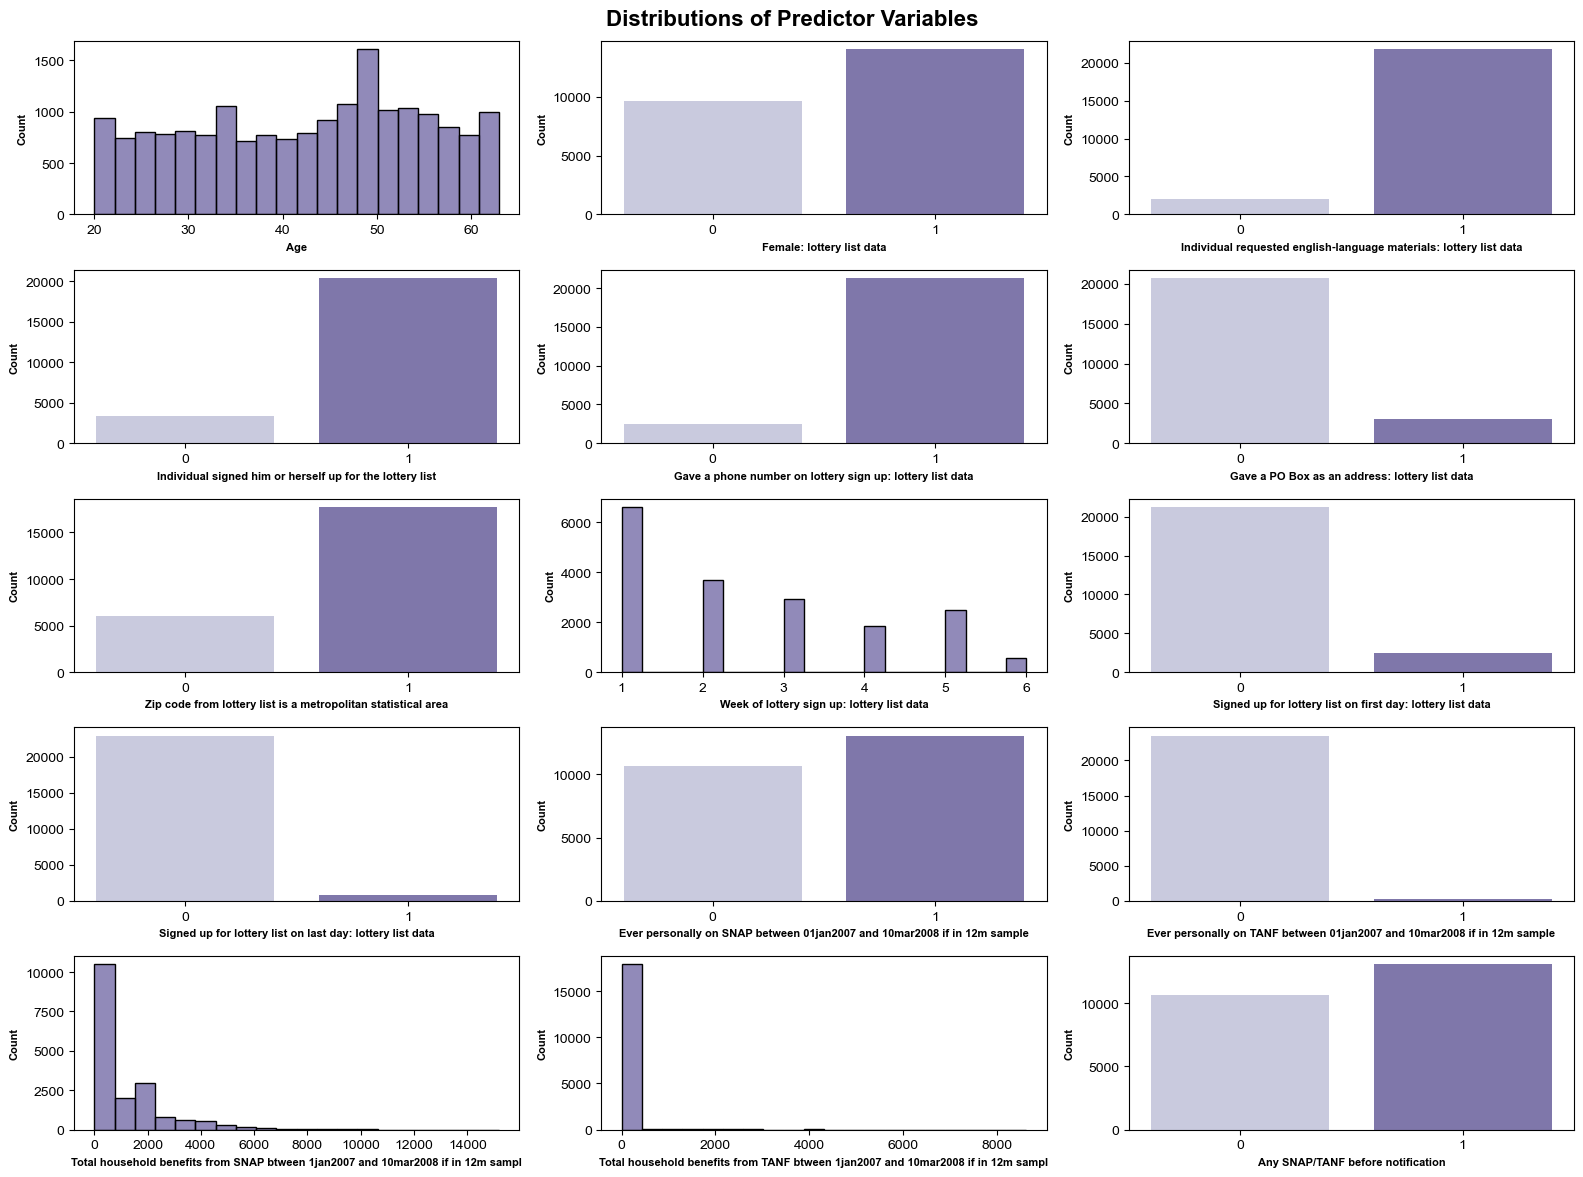

In [38]:
# Lets visualize the distribution of predictor variables in our dataset using histograms (continuous) and bar charts (binary/categorical)
# Instead of printing and displaying each histogram sequentially, lets create a clean grid layout to show it in one view
# Note: To learn if how to format the plots into a grid layout, instead of printing them all sequentially.
  # Claude Fable 5. Based on the response to prompt: "Instead of printing my plots sequentially, I want to display them in rows/columns to be more organized."
# 5 rows, 3 columns
fig, axes = plt.subplots(5, 3, figsize = (16, 12))
distribution_plots(df, predictors, "Predictor", fig, axes)
fig.savefig(f"{OUTPUT}/predictor_distributions.png")

Each panel shows the distribution of a specific predictor variable using a histogram or bar chart, depending on the data type. Immediately, we can see that the cohort is majorty female, with ages spread fairly evenly across age groups. Most respondents reported an english language preferance, individually signing up for the lottery, have a phone number, live in a metro area, were personally on SNAP between Janruary 2007 and March 2008, and signed up for the lottery in the first few weeks. Additionally, we can see that the total household benefits from SNAP or TANF appear to be highly skewed, with most respondents reporting no total household benefits, with a few reporting very high amounts.

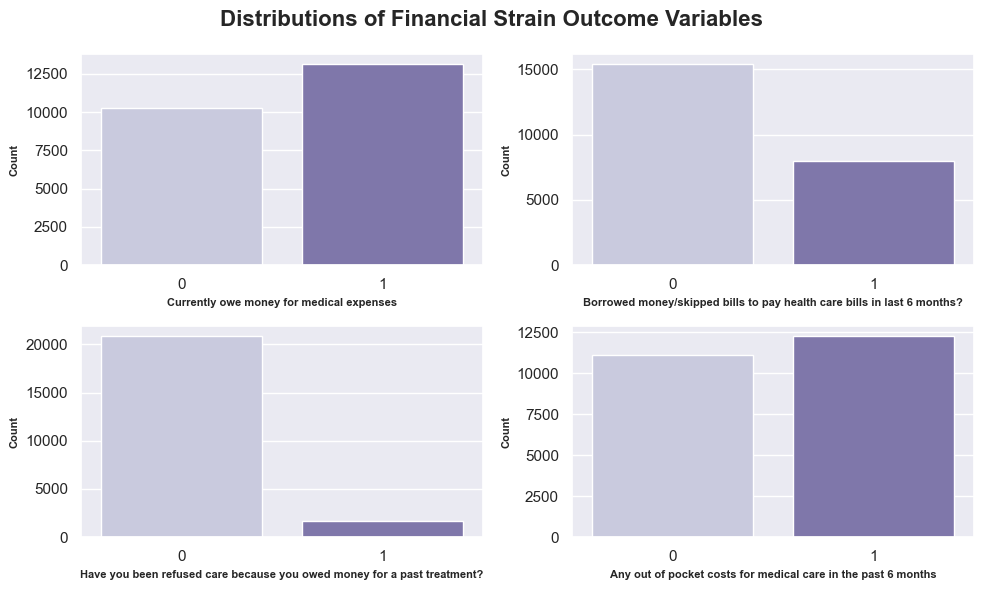

In [39]:
# Lets visualize the distribution of outcome variables in our dataset using bar charts (since they are all binary outcomes)
# Instead of printing and displaying each histogram sequentially, lets create a clean grid layout to show it in one view
# Note: To learn if how to format the plots into a grid layout, instead of printing them all sequentially.
  # Claude Fable 5. Based on the response to prompt: "Instead of printing my plots sequentially, I want to display them in rows/columns to be more organized."
# 2 rows, 2 columns
fig, axes = plt.subplots(2, 2, figsize = (10, 6))
distribution_plots(df, outcomes, "Financial Strain Outcome", fig, axes)
fig.savefig(f"{OUTPUT}/outcome_distributions.png")

Visualizing the distribution of financial strain outcomes, we can see that the majority of participants report owing money for medical expenses. Additionally, we can see that the majority of patients report out of pocket costs for medical care in the past 6 months, with some even needing to borrow money or skipping bills to pay for health care, or being refused care because they owed money for past treatment.

#### 5.5. Outcomes by Treatment Group

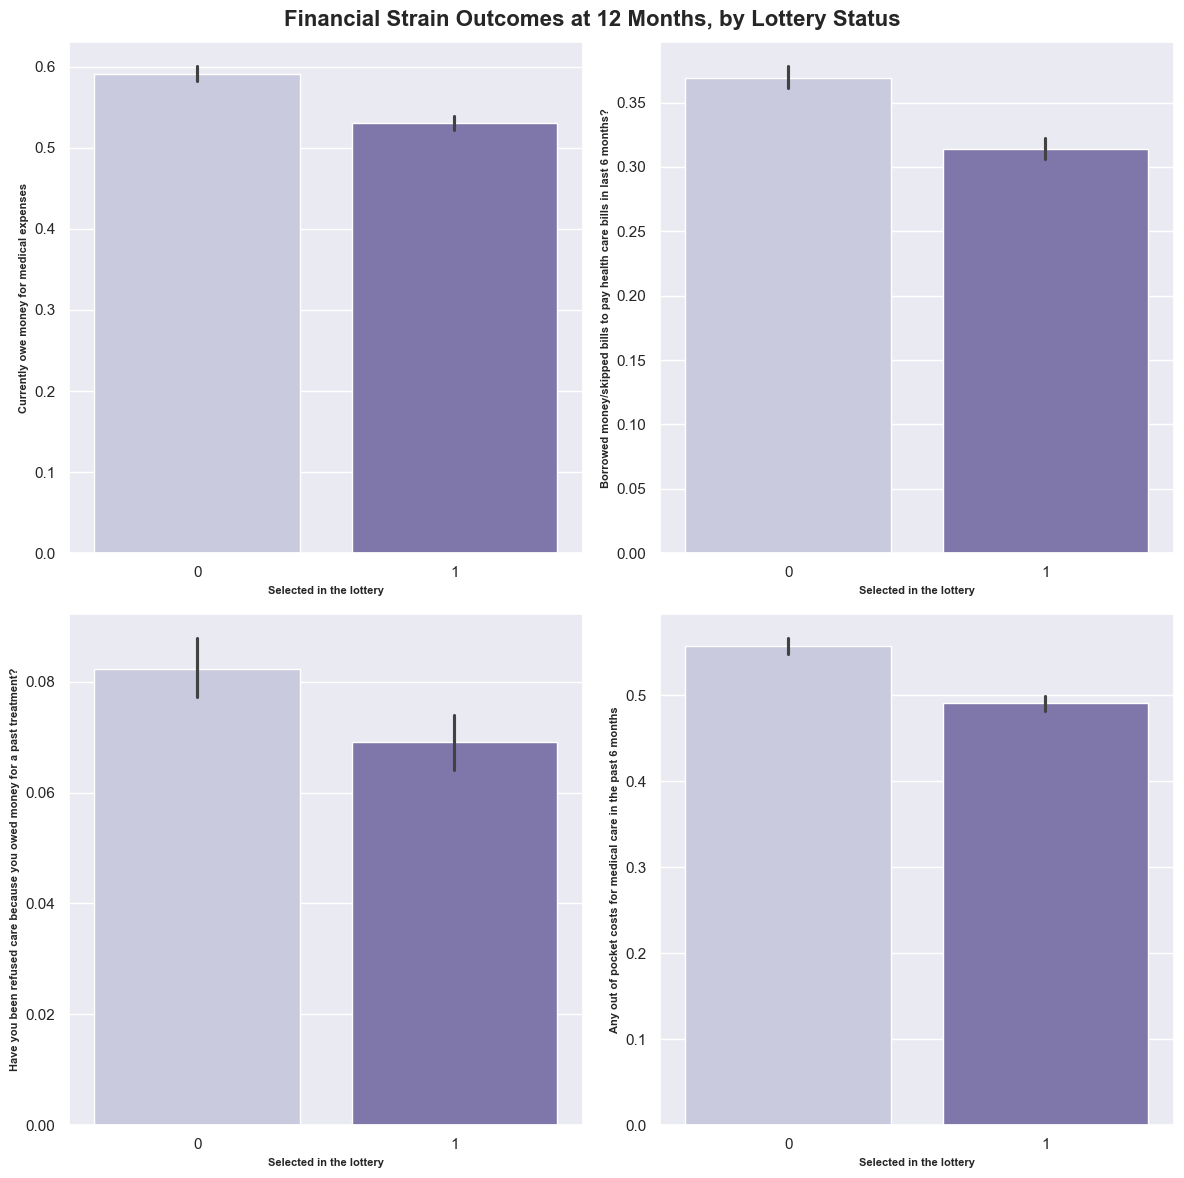

In [40]:
# Instead of printing and displaying each histogram sequentially, lets create a clean grid layout to show it in one view
# 2 rows, 2 columns
fig, axes = plt.subplots(2, 2, figsize = (12, 12))

# Loop through each variable, creating the bar chart for each
for ax, variable in zip(axes.flat, outcomes):
  # Using hue = outcome to group by treatment group, and use ax = ax for the grid layout
  # https://python-graph-gallery.com/barplot/
  sns.barplot(data = df, x = treatment, y = variable, hue = treatment, palette = "Purples", legend = False, ax = ax)
  # Set the x and y labels
  ax.set_xlabel(labels[treatment], fontsize = 8, fontweight = "bold")
  ax.set_ylabel(labels[variable], fontsize = 8, fontweight = "bold")

# Since we are using a grid layout, lets add one clean title that applies to all plots
fig.suptitle("Financial Strain Outcomes at 12 Months, by Lottery Status", fontsize = 16, fontweight = "bold")
sns.set_theme(style = "darkgrid")
# Ensure the grid layout is being applied
fig.tight_layout()
fig.savefig(f"{OUTPUT}/outcome_distributions_by_lottery_status.png")
plt.show()


When visualizing financial strain outcomes by treatment group (i.e., selected in lottery or not selected in lottery), we can immediately see that those in the selected in the lottery have lower rates of financial strain across all four outcome variables (i.e., owe money for medical expenses, borrowed money or skipped bills to pay health care bills, refused care because of medidal debt, and had to pay out of pocket for medical care in the past 6 months).

#### 5.6. Subgroup Analysis

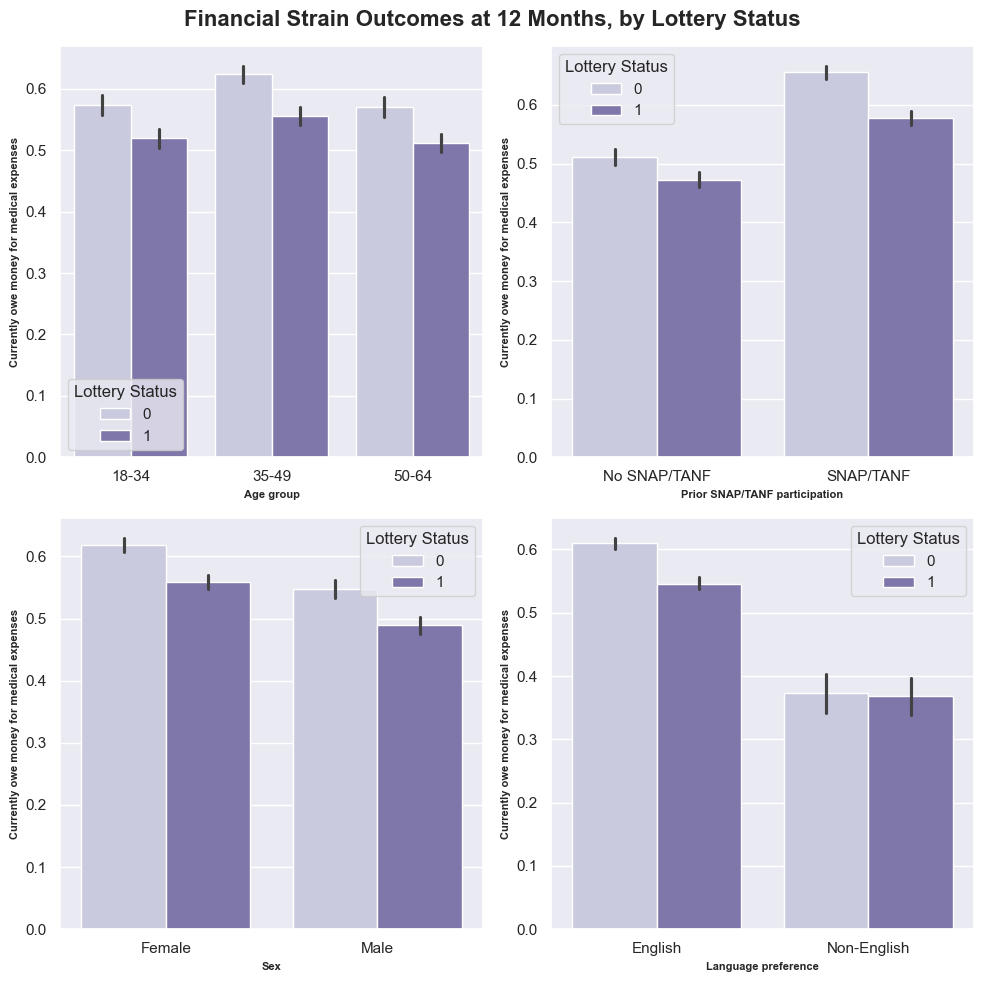

In [41]:
# Instead of printing and displaying each histogram sequentially, lets create a clean grid layout to show it in one view
# 2 rows, 2 columns
fig, axes = plt.subplots(2, 2, figsize = (10, 10))

# Loop through each variable, creating the bar chart for each
for ax, subgroup in zip(axes.flat, subgroups):
  # Using hue = outcome to group by diabetes status, and use ax = ax for the grid layout
  # https://python-graph-gallery.com/barplot/
  sns.barplot(data = df, x = subgroup, y = outcome, hue = treatment, palette = "Purples", ax = ax)
  # Set the x, y, and legend labels
  ax.set_xlabel(labels[subgroup], fontsize = 8, fontweight = "bold")
  ax.set_ylabel(labels[outcome], fontsize = 8, fontweight = "bold")
  legend = ax.get_legend()
  legend.set_title("Lottery Status")

# Since we are using a grid layout, lets add one clean title that applies to all plots
fig.suptitle("Financial Strain Outcomes at 12 Months, by Lottery Status", fontsize = 16, fontweight = "bold")
sns.set_theme(style = "darkgrid")
# Ensure the grid layout is being applied
fig.tight_layout()
fig.savefig(f"{OUTPUT}/outcome_distributions_by_subgroup.png")
plt.show()

Here, we visualized financial strain outcomes by treatment group (i.e., selected in lottery or not selected in lottery) and by subgroup (i.e., age group, prior SNAP/TANF participation, sex, and language preferance). We can see that the direction of difference between treatment groups is consistent across all subgroups (those selected in lottery have lower rates of financial strain), however, the magnitude of that difference does vary. For instance, we can see that there appears to be a larger difference between treatment groups for those with prior SNAP/TANF participation than those with not. Additionally, those with non-english language prefereance appear to have much more consistent rates across treatment groups. It will be important to investigate these differences further with a more robust subgroup analysis once during the full analysis.

#### 5.7. Predictor Correlation Matrix & Heatmap

In [42]:
# Lets create our correlation matrix using .corr(), and rename() to use the readable labels from the predictor dictionary
# Note: To learn how to create a correlation matrix in Python
  # Claude Fable 5. Based on the response to prompt: "How can I make a correlation matrix in Python, how to choose/change the method used, and how to use the values in a dictionary as the labels with the keys as the variables."
# Spearman was chosen over Pearson because snap_dollars_pre and tanf_dollars_pre appear to be right skewed
correlation_matrix = df[predictors].corr(method = "spearman").round(3)
correlation_matrix

,age,female,english,self_signup,has_phone,pobox,metro,signup_week,signup_first_day,signup_last_day,snap_pre,tanf_pre,snap_dollars_pre,tanf_dollars_pre,any_program_pre
age,1.000,-0.023,0.061,0.018,-0.005,0.083,-0.073,-0.050,0.030,-0.017,0.000,-0.058,-0.063,-0.032,-0.001
female,-0.023,1.000,0.007,0.144,0.025,-0.001,-0.002,-0.019,0.005,-0.007,0.017,0.046,0.037,0.058,0.018
english,0.061,0.007,1.000,0.129,-0.030,0.063,-0.078,-0.061,0.052,-0.010,0.196,0.004,0.076,-0.014,0.192
self_signup,0.018,0.144,0.129,1.000,-0.025,-0.001,0.027,0.027,-0.007,0.023,0.081,0.017,0.023,0.012,0.081
has_phone,-0.005,0.025,-0.030,-0.025,1.000,-0.010,0.010,0.041,-0.026,-0.030,0.035,-0.016,0.034,-0.003,0.036
pobox,0.083,-0.001,0.063,-0.001,-0.010,1.000,-0.263,0.034,-0.010,0.014,0.015,-0.013,0.002,-0.004,0.015
metro,-0.073,-0.002,-0.078,0.027,0.010,-0.263,1.000,-0.041,0.033,0.005,-0.034,0.017,-0.024,0.003,-0.034
signup_week,-0.050,-0.019,-0.061,0.027,0.041,0.034,-0.041,1.000,-0.388,0.265,-0.053,-0.001,-0.056,-0.010,-0.053
signup_first_day,0.030,0.005,0.052,-0.007,-0.026,-0.010,0.033,-0.388,1.000,-0.063,0.031,-0.007,0.028,-0.003,0.032
signup_last_day,-0.017,-0.007,-0.010,0.023,-0.030,0.014,0.005,0.265,-0.063,1.000,-0.039,0.000,-0.035,0.002,-0.039


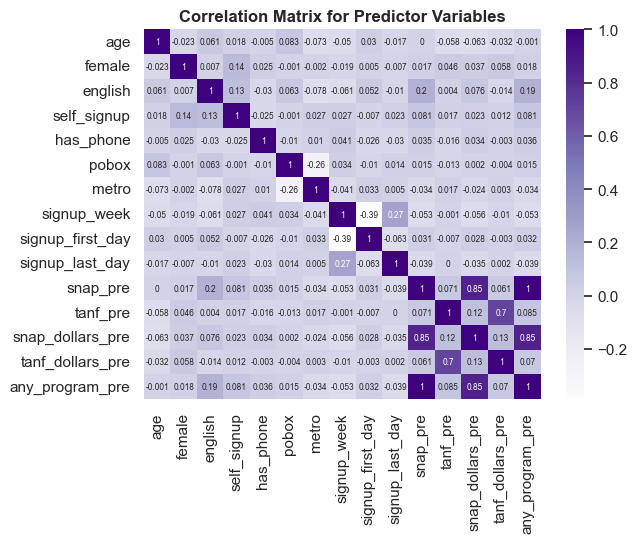

In [43]:
# Create a heatmap to visualize the correlation matrix
# Using annot = True to include the numeric labels
# https://python-graph-gallery.com/91-customize-seaborn-heatmap
sns.heatmap(correlation_matrix, annot = True, annot_kws = {"size": 6}, cmap = "Purples")
plt.title("Correlation Matrix for Predictor Variables", fontsize = 12, fontweight = "bold")
sns.set_theme(style = "darkgrid")
plt.savefig(f"{OUTPUT}/predictor_correlation_heatmap.png")
plt.show()

The matrix and heatmap report the Spearman rank correlations between each pair of predictors. Spearman was chosen for it's more robustness to skewed data and outliers, since household SNAP/TANF benefit amounts appear to be right skewed with clear outliers.

The strongest relationships were mostly by design. Any program participation (SNAP or TANF) was nearly identical to SNAP participation (0.999). Similarly, TANF participation and household TANF benefit amounts were strongly correlated (0.7), and SNAP participation and household SNAP benefit amounts were strongly correlated (0.85). Meanwhile, living in a metro area was moderately negatively correlated with reporting a PO box. With that said, the majority of relationships were only weakly correlated with each other.

## 6. Supervised Machine Learning Classification
---

This section includes:

- 6.1. Design Matrix & Cross-Validation Folds
- 6.2. Logistic Regression
- 6.3. Random Forest
- 6.4. XGBoost
- 6.5. Out-of-Fold Predictions
- 6.6. Threshold Selection
- 6.7. Performance Metrics & Overfit Check
- 6.8. ROC & Calibration Curves
- 6.9. Confusion Matrices
- 6.10. Variable Importance

<br>

**Design Matrix:** The 15 predictors are kept except for `any_program_pre`, which provides nearly identical information as `snap_pre` (Spearman 0.999) and is therefore redundant, based on the correlation matrix. `hh_size` and `wave` are stored as integers but represent categories (household size: 1-3, survey mailing waves: 1-7), so they are one-hot encoded, using one level of each as the reference.

**Cross-Validation Folds:** Lottery selection was at the household level, and members of the same household share an address, household income, and lottery outcome. If one member landed in a training fold and another in the test fold, the model would have a near-identical copy of the test case during training, introducing a form of data leakage. For that reason, folds are grouped by household, and the same five folds are reused for the machine learning classifiers (i.e., logistic regression, random forest, XGBoost) and causal inference methods (i.e., AIPW, g-computation, causal forest).


### 6.1. Design Matrix & Cross-Validation Folds

In [44]:
# First, lets build the modeling inputs that every model in the rest of the notebook will use
# Use one-hot encoding for any multi-level categories (hh_size and wave)
categorical = ["hh_size", "wave"]

# Based on the correlation matrix, we saw that any_program_pre is nearly identical to snap_pre (Spearman 0.999), so lets drop one to avoid redundancy
features = [p for p in predictors if p != "any_program_pre"] + [treatment] + categorical

# Create our design matrix: outcome, household groups, survey weights
X = pd.get_dummies(df[features], columns = categorical, drop_first = True, dtype = int)
y = df[outcome]
# We also need to account for our design variables
# Group by household id, so that memebers of the same household can be placed within the same cross validation fold (to avoid data leakage)
groups = df["household_id"]

# Print to view the final feature set
print(X.shape)
print(X.columns)

(23740, 23)
Index(['age', 'female', 'english', 'self_signup', 'has_phone', 'pobox',
       'metro', 'signup_week', 'signup_first_day', 'signup_last_day',
       'snap_pre', 'tanf_pre', 'snap_dollars_pre', 'tanf_dollars_pre',
       'treatment', 'hh_size_2', 'hh_size_3', 'wave_2', 'wave_3', 'wave_4',
       'wave_5', 'wave_6', 'wave_7'],
      dtype='object')


### 6.2. Logistic Regression

In [45]:
# For model fitting, we need observed outcomes only (no NAs)
fit_data = y.notna()
X_fit = X[fit_data]
y_fit = y[fit_data].astype(int)
groups_fit = groups[fit_data]

# Lets create folds based on household id so that members of the same household are not spread across training and test sets to avoid potential data leakage
# Note: To learn how to create folds based on household id
  # Claude Fable 5. Based on the response to prompt: "How can I create cross-validation folds, while ensuring that members of the same household are not split between training and test sets?"
n_folds = 5
folds = list(GroupKFold(n_splits = n_folds).split(X_fit, y_fit, groups = groups_fit))


In [46]:
# First, lets perform the baseline: logistic regression with scaling, since the predictors are on different scales
logistic_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000))

### 6.3. Random Forest

In [47]:
# Next, lets create our random forest classifier
# First, we need to define the hyperparameter grid for tuning
# Note: To learn how to perform hyperparameter tuning for random forest and XGBoost
  # Claude Fable 5. Based on the response to prompt: "I am building random forest and xgboost models, how can I perform hyperparameter tuning and how do I decide on the default grid?"
rf_grid = {
    # n_estimators: how many trees to average
    "n_estimators": [100, 250, 500],
    # max_depth: how deep each tree can go
    "max_depth": [None, 4, 6, 8, 10],
    # min_sample_leaf: smallest group a tree is allowed to get split down to
    "min_samples_leaf": [5, 25, 50, 100],
    # max_features: how many predictors each split gets to choose from
    "max_features": ["sqrt", 0.5]
}

# Random search over 20 combinations, scored based on brier and using the household-grouped folds
# Random search helps reduce the computation time by randomly selecting combinations across the grid, rather than running all possible combination
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state = SEED, n_jobs = -1),
    rf_grid, n_iter = 20, scoring = "neg_brier_score", cv = folds, random_state = SEED
)

# Fit, identify, and report the best combination and its cross-validated brier score
rf_search.fit(X_fit, y_fit)
print("Random forest:", rf_search.best_params_, round(-rf_search.best_score_, 4))

Random forest: {'n_estimators': 500, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 6} 0.2369


The search selected 500 trees, a maximum depth of 6, a minimum of 5 observation per leaf, and half the features considered at each splot, for a cross-validated Brier score of 0.2369.

### 6.4. XGBoost

In [48]:
# Now, lets create our xgboost classifier
# Simarily to random forest, lets define the hyperparameter grid for tuning
xgb_grid = {
    # n_estimators: how many trees to add (this time, sequentially)
    "n_estimators": [100, 250, 500],
    # max_depth: how deep each tree can go
    "max_depth": [4, 6, 8, 10],
    # learning_rate: how big a step each new tree takes
    "learning_rate": [0.02, 0.05, 0.1],
    # min_child_weight: smallest group a tree is allowed to split down to
    "min_child_weight": [1, 5, 20],
    # subsample: fraction of rows each tree seees
    "subsample": [0.7, 0.9]
}

# Random search over 25 combinations, scored on brier and using the household-grouped folds
xgb_search = RandomizedSearchCV(
    XGBClassifier(random_state = SEED, n_jobs = -1),
    xgb_grid, n_iter = 25, scoring = "neg_brier_score", cv = folds, random_state = SEED
)

# Fit, identify, and report the best combination and its cross-validated brier score
xgb_search.fit(X_fit, y_fit)
print("xgboost:", xgb_search.best_params_, round(-xgb_search.best_score_, 4))

xgboost: {'subsample': 0.9, 'n_estimators': 100, 'min_child_weight': 20, 'max_depth': 6, 'learning_rate': 0.02} 0.2373


The search selected 100 boosting rounds at a learning rate of 0.02, depth 6, minimum child weight of 20, and 90% row subsampling, for a cross-validated Brier score of 0.2373. The result is effectively tied with random forest (0.2369).

### 6.5. Out-of-Fold Predictions

In [49]:
# Lets create a classification models dictionary, so that we can loop through it to get the final classification metrics and compare
classification_models = {
    "logistic": logistic_model,
    "random_forest": rf_search.best_estimator_,
    "xgboost": xgb_search.best_estimator_
}

In [50]:
# We want out-of-fold predicted probabilities for each model, using the household
# Four folds used to fit the model, and one saved to score
# So every respondent is predicted by a model that has never seen their household
oof = pd.DataFrame(index = X_fit.index, columns = classification_models.keys(), dtype = float)
# Save fitted fold models for later use
fold_models = {name: [] for name in classification_models}

# Loop through and fit / score each model (logistic regression, random forest, and xgboost)
# Note: To learn how to fit each model using the folds
  # Claude Fable 5. Based on the response to prompt: "Now that I have the cross-validation folds, how can we use them for the train-test split?"
for name, model in classification_models.items():
    for train, test in folds:
        # Fit the model on the four folds
        model.fit(X_fit.iloc[train], y_fit.iloc[train])
        # Score the model on the held-out fold
        oof.iloc[test, oof.columns.get_loc(name)] = model.predict_proba(X_fit.iloc[test])[:, 1]
        fold_models[name].append(copy.deepcopy(model))

oof.describe().T


,count,mean,std,min,25%,50%,75%,max
logistic,23450.0,0.560733,0.093605,0.229624,0.507047,0.572402,0.628688,0.799169
random_forest,23450.0,0.560895,0.092993,0.193369,0.502713,0.565389,0.625115,0.779194
xgboost,23450.0,0.560918,0.087995,0.217088,0.507180,0.567329,0.625037,0.721677


The three sets of out-of-fold predictions are nearly identical in location and spread: mean 0.5631 (matching with the base rate), standard deviation about 0.09, and a range of roughly 0.2 to 0.8. No model pushes predictions toward 0 or 1, which indiciates the weak separation between those with and without medical debt based on these features.

### 6.6. Threshold Selection

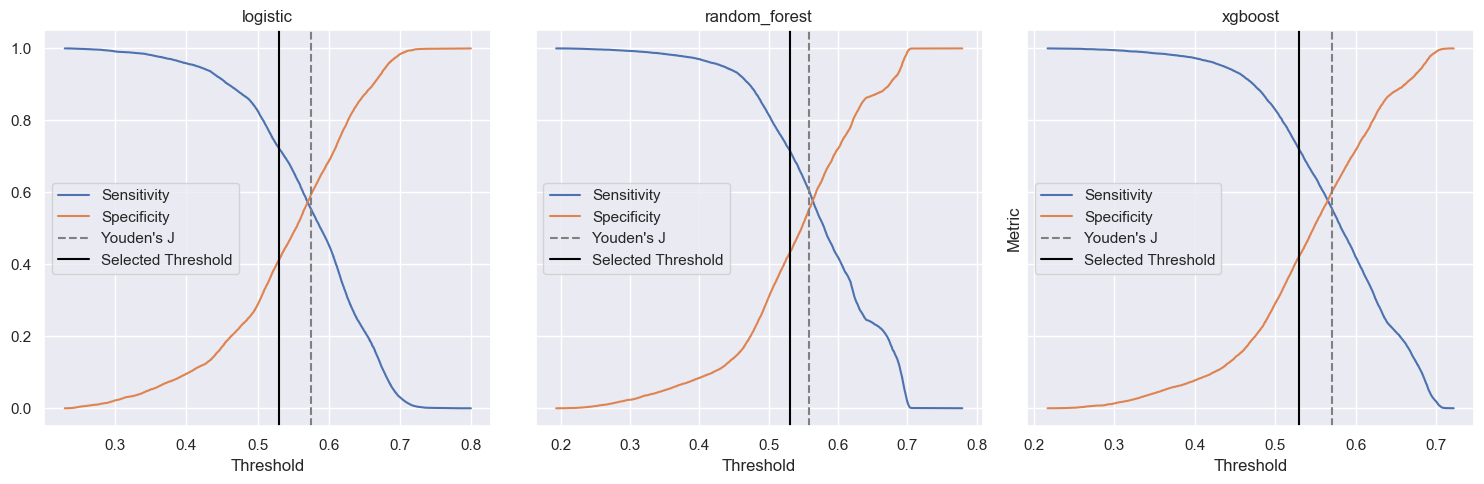

In [51]:
# Next, lets determine our threshold
# To do this, we will create a plot to visualize sensitivity and specificity for each model
# Since we want to prioritize sensitivity (avoiding false negatives), lets select a threshold that
# maintains high sensitivity, at a slight cost of specifcity (compared to Youden's J)
# Note: To learn how to create a plot visualizing the sensitivity/specificity tradeoff
  # Claude Fable 5. Based on the response to prompt: "Instead of using F1-maximization or Youden's J, I want to select the threshold based on a sensitvity-specificty tradeoff, based on the studies goals (prioritze sensitivity, without losing too much specificity)"
chosen_threshold = 0.53
fig, axes = plt.subplots(1, 3, figsize = (15, 5), sharey = True)
# For each model, lets create a sensitivity vs specificity plot
for ax, name in zip(axes, classification_models):
    # First, retrieve the out-of-fold predicted probabilities for this model
    p = oof[name]
    # False positive rate and false positive rate at every cutoff
    fpr, tpr, threshold = roc_curve(y_fit, p)
    ax.plot(threshold, tpr, label = "Sensitivity")
    ax.plot(threshold, 1 - fpr, label = "Specificity")
    # Plot Youden's J (maximizes sensitivity + specificty), for reference
    ax.axvline(threshold[np.argmax(tpr - fpr)], linestyle = "--", color = "grey", label = "Youden's J")
    # After viewing the plots and deciding a threshold, lets add a line for our selected threshold, so it is easy to visualize the
    # tradeoff between sensitivity and specificity
    ax.axvline(chosen_threshold, color = "black", label = "Selected Threshold")
    # Add plot title, label and legend
    ax.set_title(name)
    ax.set_xlabel("Threshold")
    ax.legend()
ax.set_ylabel("Metric")
plt.tight_layout()

A classification threshold converts predicted probabilities those flagged as having medical debt / no medical debt. Two automatic approaches were tried and ultimately rejected. First, maximizing F1 chose a threshold of near 0.35 that labeled almost every respondent as having medical debt, so this was not useful or appropriate. Second, Youden's J (sensitivity + specificity - 1) chose a threshold near the base rate but weights the two error types equally, which does not properly reflect our priorities here.

The threshold was instead chosen based on the sensitivity and specificty plot above, with sensitivity (recall) as the primary metric. For our purposes, missing someone who will incur medical debt is higher cost than incorrectly flagging someone as having medical debt when they do not. A threshold of 0.53, just below the base rate, prioritizes sensitivity without labeling everyone as having medical debt. Moving the threshold from 0.55 to 0.53 raised sensitivity from about 0.65 to 0.72 at a cost of about 0.08 in specificity.

### 6.7. Performance Metrics & Overfit Check

In [52]:
# Each model refit on the full fit sample, used for the overfitting check, feauture importance, and SHAP
full_models = {name: copy.deepcopy(m).fit(X_fit, y_fit) for name, m in classification_models.items()}

# Now, lets perform an overfitting check, to make sure the model generalizes well to new data
# Loop through each classification model (logistic regression, random forest, xgboost), and determine the train and set set auc and brier score
# Note: To learn how to gather training set predictions, to test for overfitting
  # Claude Fable 5. Based on the response to prompt: "I have test set-based predictions, but now how can I retrieve training set-based predictions, so that I can compare the two for overfitting."
rows = []
for name in classification_models:
    # Retrieve the predictions for the training set
    p_train = full_models[name].predict_proba(X_fit)[:, 1]
    # Save them to a list, so that we can display and compare them in a single table
    rows.append({
        "Model": name,
        "Train AUC": roc_auc_score(y_fit, p_train),
        "Test AUC": roc_auc_score(y_fit, oof[name]),
        "Train Brier": brier_score_loss(y_fit, p_train),
        "Test Brier": brier_score_loss(y_fit, oof[name]),
    })


# Now, lets group the scores by model and compare the train vs test set auc and brier score to ensure they are relatively consistent and that there is no overfitting
overfit_check = pd.DataFrame(rows).set_index("Model")
overfit_check.round(3)

,Train AUC,Test AUC,Train Brier,Test Brier
Model,,,,
logistic,0.606,0.602,0.238,0.238
random_forest,0.634,0.609,0.233,0.237
xgboost,0.640,0.608,0.232,0.237


Logistic regression shows essentially no gap between full-sample and out-of-fold AUC (0.606 vs 0.602). The tree models show a small gap of 0.03 (0.634 vs 0.609 for the random forest, 0.640 vs 0.608 for XGBoost), which is expected from refitting on the same data. Brier scores are flat at 0.232 to 0.238 across all models and both evaluations. The training values are only used for this overfit check, moving forward, only out-of-fold values will be used and reported.

In [53]:
# Loop through each classification model (logistic regression, random forest, xgboost) to retrieve the classification metrics
rows = []
for name in classification_models:
    # Clip to avoid logit of exactly 0 or 1 in the calibration regression
    p = oof[name].clip(0.001, 0.999)
    # Determine each respondents prediction (debt or no debt), based on their probability and the selected threshold
    # If probability is at or above the threshold, then classify as debt (1)
    # If probability is below the threhsld, then classify as no debt (0)
    pred = (p >= chosen_threshold).astype(int)
    # Determine the calibration slope
    cal = sm.Logit(y_fit, sm.add_constant(logit(p))).fit(disp = 0)
    # Retrieve the true negative (tn), false positive (fp), false negative (fn) and true positive (tp) for determining sensitivity and specificity
    tn, fp, fn, tp = confusion_matrix(y_fit, pred).ravel()
    # Add all metrics for each model to a single list, so that we can display and compare them in a single table
    rows.append({
        "Model": name,
        "Threshold": chosen_threshold,
        "AUC": roc_auc_score(y_fit, p),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Accuracy": accuracy_score(y_fit, pred),
        "Brier": brier_score_loss(y_fit, p),
        "Calibration Slope": cal.params.iloc[1],
        "Recall": recall_score(y_fit, pred),
        "Precision": precision_score(y_fit, pred),
        "F1": f1_score(y_fit, pred)
    })

# Print the classification metrics for all three moodels
classification_metrics = pd.DataFrame(rows).set_index("Model").round(3)
classification_metrics


,Threshold,AUC,Sensitivity,Specificity,Accuracy,Brier,Calibration Slope,Recall,Precision,F1
Model,,,,,,,,,,
logistic,0.53,0.602,0.722,0.412,0.586,0.238,0.954,0.722,0.611,0.662
random_forest,0.53,0.609,0.718,0.431,0.592,0.237,1.047,0.718,0.617,0.664
xgboost,0.53,0.608,0.717,0.423,0.588,0.237,1.089,0.717,0.614,0.662


At the selected threshold of 0.53, all three models sit at an AUC of 0.60 to 0.61, sensitivity of 0.72, specificity of 0.41 to 0.43, and accuracy of 0.59. Calibration slops near 1 (0.95 to 1.09) indicate that predicted probabilities are on the right scale, so a prediction of 0.65 corresponds to roughly a 65% observed rate of medical debt. Recall, the primary metric, 0.72 for all three models with a precision of 0.61 to 0.62, indicating that about three in five of those flagged as having medical debt actually do, compared to the base rate of 0.56.

There are two key takeaways from these performance metrics. First, an AUC of 0.60 indicates weak discrimination ability. The predictors are pre-lottery administrative variables (age, sex, language, prior benefit recipient, signup behavior), plus the lottery selection indicator. However, medical debt at 12 months likely depends largely on health status, health shocks, income, and existing debt that are not included here. Second, the near-equality of logistic regression, random forest, and XGBoost indicates that there is likely little nonlinearity or interactions within these features. For those reasons, logistic regressionis likely the simplest and most interpretable model for this task, with random forest and XGBoost as useful robustness checks.

### 6.8. ROC & Calibration Curves

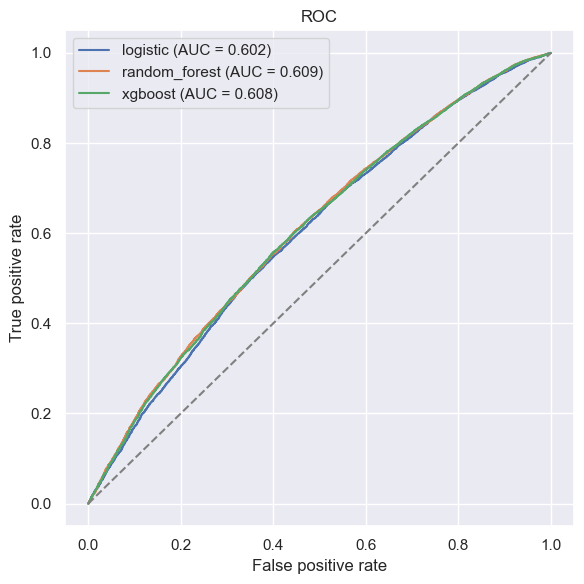

In [54]:
# Lets compare our three models using an ROC curve on the out-of-fold predictions
fig, ax = plt.subplots(figsize = (6, 6))
# First, loop through each classification model (logistic regression, random forest, and xgboost)
# and determine the false positive rate and true positive rate using the roc_curve() sklearn function
# Then, we can plot each one, along with its text label / legend
for name in classification_models:
    fpr, tpr, _ = roc_curve(y_fit, oof[name])
    ax.plot(fpr, tpr, label = f"{name} (AUC = {classification_metrics.loc[name, "AUC"]:.3f})")
# For reference, also plot the 0.5 line
ax.plot([0, 1], [0, 1], linestyle = "--", color = "grey")
# Add x and y axis labels, and a plot title
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC")
# Add the legend, using the label created earlier
ax.legend()
fig.savefig(f"{OUTPUT}/roc.png")
plt.tight_layout()

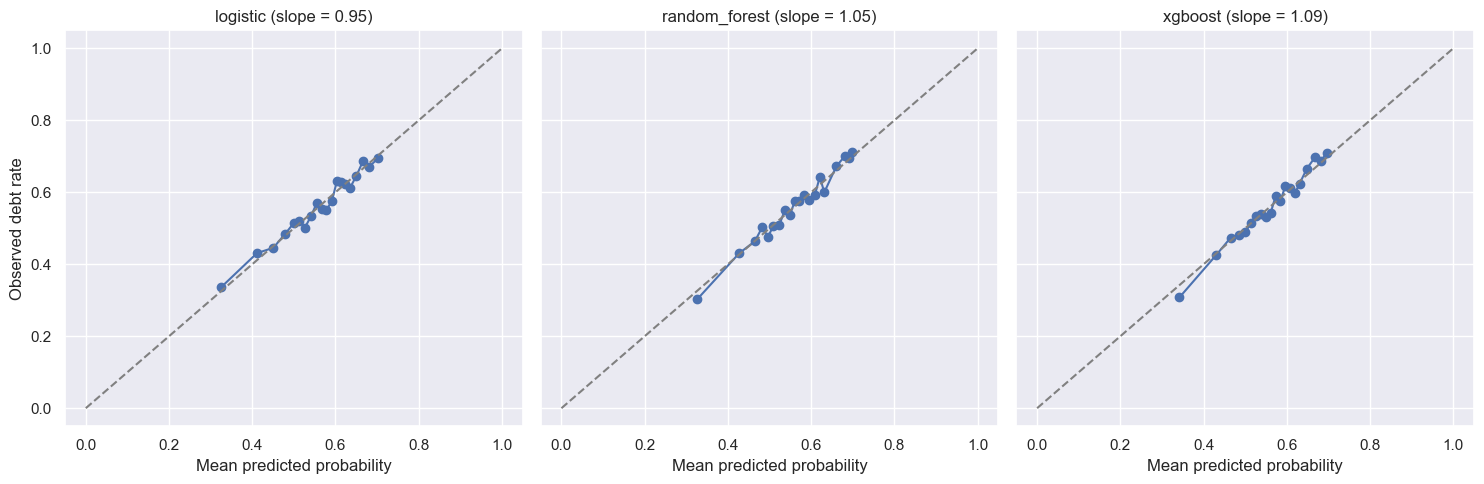

In [55]:
# Next, lets check and compare the calibration curves of each model
# Note: To learn how to create create a calibration curve and confusion matrix plots
  # Claude Fable 5. Based on the response to prompt: "How can I create a calibration curve and confusion matrix plots in Python for all three classification model?"
fig, axes = plt.subplots(1, 3, figsize = (15, 5), sharey = True)
for ax, name in zip(axes, classification_models):
    # Split respondents into 20 bins (by predicted probability), and determine the mean prediction for each bin
    frac_props, mean_pred = calibration_curve(y_fit, oof[name], n_bins = 20, strategy = "quantile")
    # Plot the bins mean prediction vs observed debt rate
    ax.plot(mean_pred, frac_props, marker = "o")
    # Add a reference line for perfect calibration
    ax.plot([0, 1], [0, 1], linestyle = "--", color = "grey")
    # Add a title, including the calibration slope for each model
    ax.set_title(f"{name} (slope = {classification_metrics.loc[name, 'Calibration Slope']:.2f})")
    ax.set_xlabel("Mean predicted probability")
# Add one y axis label, to apply across all three plots (since its consistent, and reduces clutter)
axes[0].set_ylabel("Observed debt rate")
fig.savefig(f"{OUTPUT}/calibration.png")
plt.tight_layout()


Observed rates track predicted probabilities closely along the diagonal across the full range of predictions (about 0.3 to 0.75). The models are appear to be appropriately confident across all points, consistent with the calibration slopes of 0.95 (logistic regression), 1.05 (random forest), and 1.09 (XGBoost).

### 6.9. Confusion Matrices

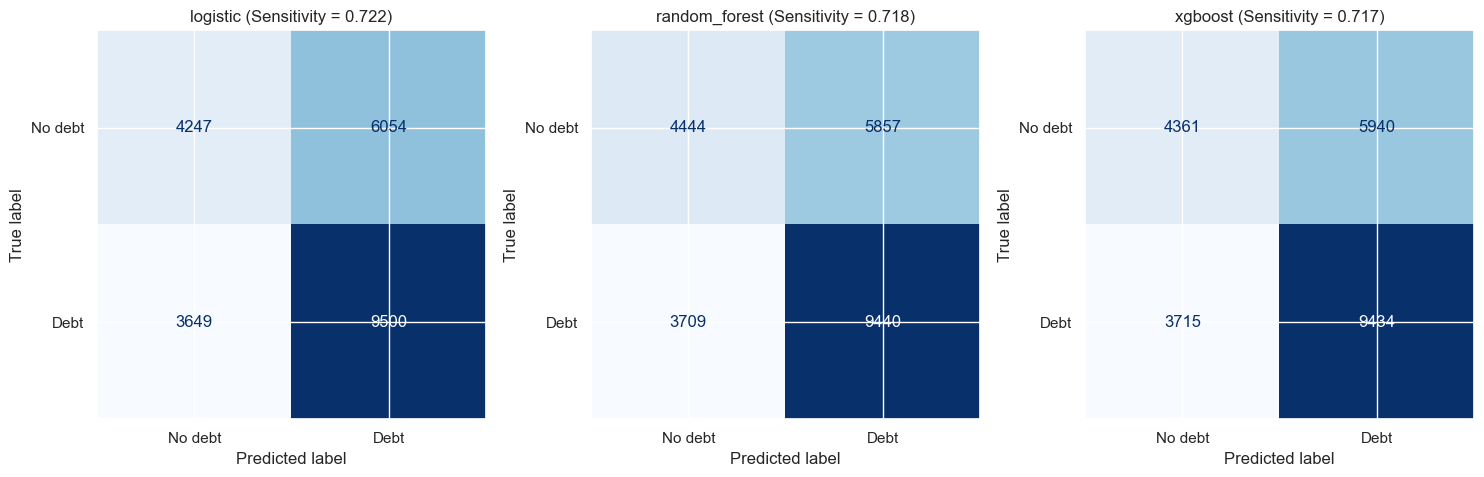

In [56]:
# Lets create a confusion matrix for each model
fig, axes = plt.subplots(1, 3, figsize = (15, 6))
for ax, name in zip(axes, classification_models):
    # Turn the out-of-fold probabilities into 0/1 labels at the selected threshold
    pred = (oof[name] >= classification_metrics.loc[name, "Threshold"]).astype(int)
    # Create the confusion matrix
    cm = confusion_matrix(y_fit, pred)
    # Display the confusion matrix
    ConfusionMatrixDisplay(cm, display_labels = ["No debt", "Debt"]).plot(cmap = "Blues", ax = ax, colorbar = False)
    # Add a title, including the value for sensitivity, since that is our priority metric
    ax.set_title(f"{name} (Sensitivity = {classification_metrics.loc[name, "Sensitivity"]:.3f})")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/confusion_matrix.png")



Each model correctly identifies about 9,400 to 9,500 of 13,149 respondents with medical debt and misses 3,650 to 3,700. For those without medical debt, only 4,250 to 4,450 of 10,301 are correctly classified, with 5,850 to 6,050 are incorrectly flagged as having medical debt. False positive outnumber false negatives roughly 1.6 to 1, which is the intended consequence of the threshold, where the cost of missing a participant with medical debt outweights the cost of flagging a participant with no medical debt.

### 6.10. Variable Importance

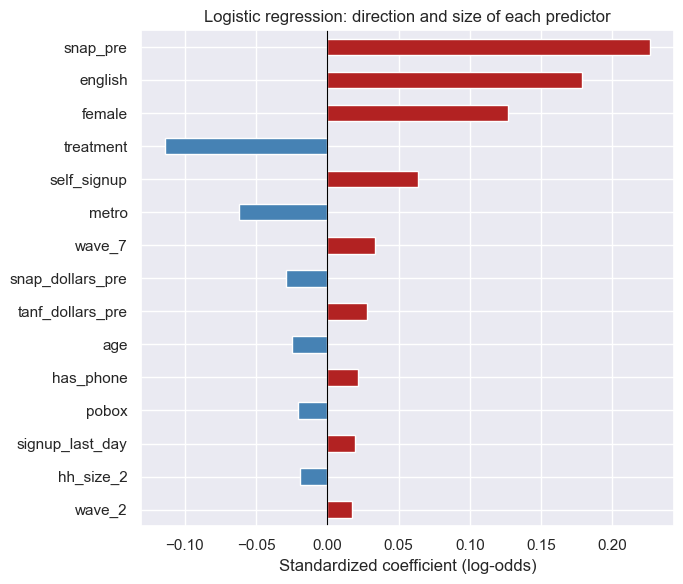

In [57]:
# Lets also plot the logistic regression coefficients, to show the direction and magnitude of each
# Note: To learn how to create logistic regression coefficient, permutation importance, and SHAP plots
  # Claude Fable 5. Based on the response to prompt: "How can I create plots for logistic regression coefficients, permutation importance (logistic regression, random forest, and xgboost), and SHAP (xgboost only)"
coef = pd.Series(full_models["logistic"].named_steps["logisticregression"].coef_[0], index = X_fit.columns)
# Now, rank by absolute size, while maintaining the direction
coef = coef.reindex(coef.abs().sort_values(ascending = False).index).head(15)
fig, ax = plt.subplots(figsize = (7, 6))
# Lets also color the bars based on direction, red = increases log odds of medical debt, blue = decreases log odds of medical debt
coef.plot.barh(ax = ax, color = np.where(coef > 0, "firebrick", "steelblue"))
ax.axvline(0, color = "black", linewidth = 0.8)
# Invert y axis so the largest absolute size is on the top
ax.invert_yaxis()
ax.set_xlabel("Standardized coefficient (log-odds)")
ax.set_title("Logistic regression: direction and size of each predictor")
plt.tight_layout()

Prior SNAP recipient (0.23), English as preferred language (0.18), and female sex (0.13) are the strongest positive predictors of medical debt. The selected in lottery indicator has the fourth magnitude and is negative (-0.11), consistent with the protective effect estimated from a Medicaid insurance coverage offer. Metro residence appeared to be mildly protective. Signup timing, giving a phone number at signup, and giving a PO box as an address contributed relatively little. Since coefficients are based on the standardized features, the magnitudes are comparable.

Additionally, the positive coefficient for English language preferance is worth noting. This may reflect differences in health care use and billing exposure rather than a direct effect of language, and is investigated further during the subgroup analysis in Section 8.


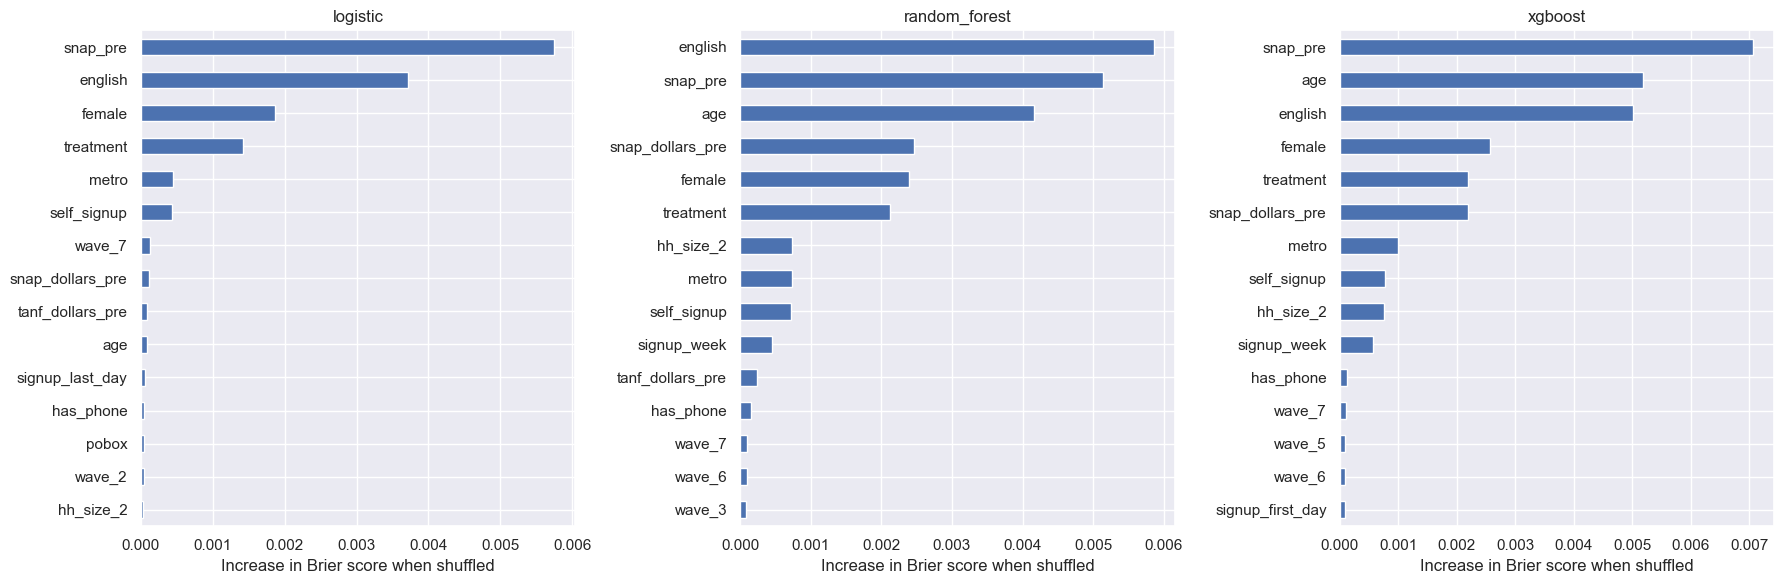

In [58]:
# Now, lets show how much each predictor matters for each model using permutation importance, which
# shows how much worse the brier score gets when that predictor is scrambled
fig, axes = plt.subplots(1, 3, figsize = (18, 6))
for ax, name in zip(axes, classification_models):
    # Shuffle each column 5 times and average the drop in performance
    perm = permutation_importance(full_models[name], X_fit, y_fit, scoring = "neg_brier_score", n_repeats = 5, random_state = SEED)
    imp = pd.Series(perm.importances_mean, index = X_fit.columns).sort_values(ascending = False)
    imp.head(15).plot.barh(ax = ax)
    # Lets put the largest at the top
    ax.invert_yaxis()
    ax.set_title(name)
    ax.set_xlabel("Increase in Brier score when shuffled")
plt.tight_layout()

Permutation importance measures how much the Brier score worsens when a feature's values are shuffled. The ordering matches the logistic coefficients: prior SNAP recipient (0.0058), English as the preferred language (0.0037), female (0.0019), and the selected in lottery indicator (0.0014) are the main features whose removal meaningfully degrades prediction.

The ordering within the top group differs by model in a few key ways. For logistic regression, age ranks tenth with negligible importance, but both tree models (random forest and XGBoost) place age in their top three (second for XGBoost, third for random forest), and the random forest also promotes prior SNAP dollars to fourth. This may indicate that the tree models identify a nonlinear relationship between age and medical debt that the logistic regression misses.



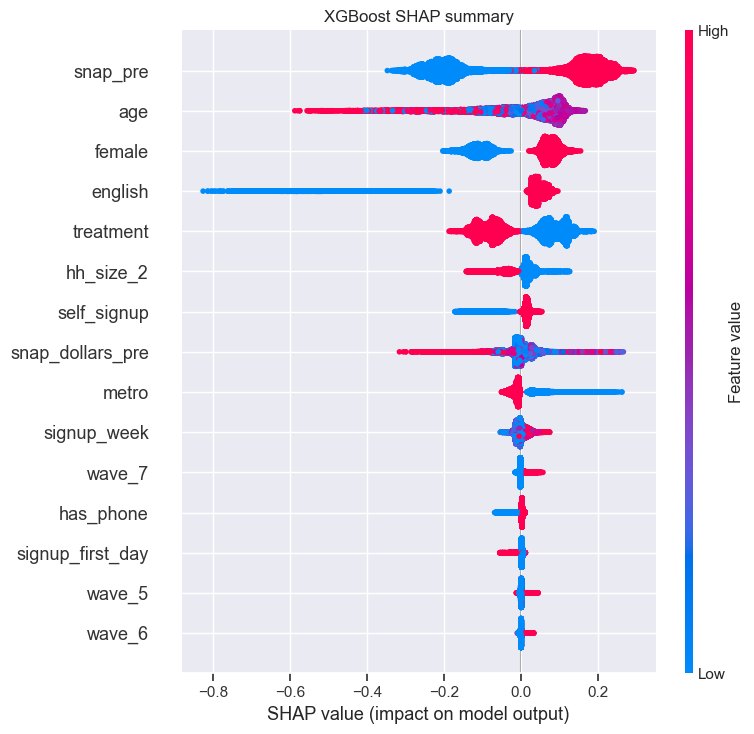

In [59]:
# Now, lets get SHAP values for the XGBoost model
# Each value is one predictors contribution to one respondents prediction, relative to the average
explainer = shap.TreeExplainer(full_models["xgboost"])
shap_values = explainer.shap_values(X_fit)
shap.summary_plot(shap_values, X_fit, max_display = 15, show = False)
plt.title("XGBoost SHAP summary")
plt.tight_layout()

SHAP values decompose each XGBoost prediction into per-feature contributions on the log-odds scale, and mean absolute SHAP ranks features by the average size of that contribution. Prior SNAP recipient tops the list at 0.19, roughly twice any other feature. Age, female, English, and the selected in lottery indicator form a second tier at 0.085 to 0.09, with a sharp drop to the third tier of household size of 2, self signup, prior SNAP dollars, and metro residence at 0.025 to 0.027.

## 7. Causal Inference

---

This section includes:

- 7.1. Propensity Score Stratum & Survey Weights
- 7.2. Covariate Balance Check
- 7.3. Intention-to-Treat (ITT): OLS
- 7.4. Local Average Treatment Effect (LATE): 2SLS
- 7.5. G-Computation
- 7.6. AIPW
- 7.7. Summary of Causal Estimates

<br>

**Propensity Score:** AIPW needs each respondent's probability of recieving the treatment (Medicaid offer). Since this study used a "lottery" design, the lottery drew individuals at random. However, households with more listed members had more chances to be drawn, so the offer rate rises with household size. The 12-month survey was also send and completed in waves tied to the eight lottery drawings, where the share of repsondents receiving offers differed across waves. Once household size and survey wave are fixed, the probability of recieving treatment was randomized. So each respondent's propensity is calculate as the share of people in their household-size by wave group who got an offer, weighted by the survey weights. The section also confirms that every group had some winners and some losers (no propensity score was near 0 or 1), which is a requirement for AIPW to compare the two arms within every group.

### 7.1. Causal Setup: Propensity Score Stratum & Survey Weights

In [60]:
# Lets check if the distribution of treatments is consistent across waves
# If not, we will need to account for that in our propensity score
# Note: To learn how to check the distribution of treatments design variables and pre-lottery variables
  # Claude Fable 5. Based on the response to prompt: "Before conducting the causal analysis, I want to compare the distributions between design variables (household size and survey wave) and all covariates
  # to ensure that the randomization "lottery" worked"
df.groupby(["hh_size", "wave"]).apply(lambda g: np.average(g["treatment"], weights = g["weight"])).unstack()

/var/folders/p8/7pvnb33s3fl9qv7808n20z_h0000gn/T/ipykernel_2678/555457878.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(["hh_size", "wave"]).apply(lambda g: np.average(g["treatment"], weights = g["weight"])).unstack()


wave,1,2,3,4,5,6,7
hh_size,,,,,,,
1,0.608113,0.602930,0.645898,0.436919,0.442935,0.427705,0.346493
2,0.696955,0.738527,0.714314,0.550076,0.517096,0.372759,0.365343
3,0.797623,0.919893,0.914790,NaN,NaN,NaN,NaN


The treated share is not constant across household sizes and waves. Within a wave, it the proportion of those teated rises with household size (e.g., 0.61, 0.70, 0.80 for wave 1), and within householdd size it falls across waves (e.g., drops from 0.61 in wave 1 to 0.35 in wave 7 for single-person households). These are features of the study design, where larger households have more draws and earlier waves were tied to earlier drawings. Moving forward, the propensity score will defined per household size by wave cell, to account for these design patterns in the causal models.

In [61]:
# We also need to incorporate for the survey weights, to ensure the estimates are representative of the full lottery list rather than only those who responded
w = df["weight"]
w_fit = w[fit_data]
# Create a treatment indicator for the fit sample
t_fit = df.loc[fit_data, treatment]
# Drop the treatment variable from the covariates, since that is handled seperately in the causal methods
X_causal = X_fit.drop(columns = [treatment])

# Now, lets calculate our propensity scores, or the respondents probability of receiving treatment (lottery offer)
# Based on the study design, we know that the probability of treatment is based on household size
# And based on the distriubtion above, we can also see that it is associated with the survey wave
e_offer = (df.groupby(["hh_size", "wave"])[["treatment", "weight"]]).apply(lambda g: np.average(g["treatment"], weights = g["weight"]))
# Assign each respondent the offer rate for their group (household size x wave)
df["e_offer"] = df.set_index(["hh_size", "wave"]).index.map(e_offer)
# Finally, lets confirm that all values are within 0 and 1 (no values should be exactly or approximately 0 or 1), to confirm that every group has both
# winners and non-winners, so that all respondents had some chance of recieving treatment
df["e_offer"].describe()

count    23740.000000
mean         0.500365
std          0.126233
min          0.346493
25%          0.427705
50%          0.442935
75%          0.608113
max          0.919893
Name: e_offer, dtype: float64

Every respondent has a propensity score, ranging from 0.35 to 0.92. No cell is near 0 or 1, so every stratum contains both winners and non-winners and the positivity assumption holds.

In [62]:
# Check for NA propensity score, since every respondent should have a propensity score
check("PROPENSITY SCORE MISSINGNESS CHECK", df["e_offer"].notna().all())
check("PROPENSITY SCORE BOUNDARY CHECK", df["e_offer"].between(0.05, 0.95).all(), f"min {df['e_offer'].min():.3f}, max {df['e_offer'].max():.3f}")

[PASS] PROPENSITY SCORE MISSINGNESS CHECK
[PASS] PROPENSITY SCORE BOUNDARY CHECK: min 0.346, max 0.920


### 7.2. Covariate Balance Check

In [63]:
# Create a new sample for regression-based estimates
cf = df.loc[fit_data].copy()
# Define the fixed effects for the design strata (household size interacted with survey wave)
design_fe = "C(hh_size) * C(wave)"
# Also, lets create a variable for the pre-lottery covariates that we want to check the balance for
balance_variables = [p for p in predictors if p not in ["any_program_pre"]]

rows = []
for variable in balance_variables:
    m = smf.wls(f"{variable} ~ {treatment} + {design_fe}", data = cf, weights = cf["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": cf["household_id"]})
    rows.append({
        "Variable": variable,
        "Control Mean": cf.loc[cf[treatment] == 0, variable].mean(),
        "Treatment Mean": cf.loc[cf[treatment] == 1, variable].mean(),
        "SE": m.bse[treatment],
        "p": m.pvalues[treatment]
    })
balance = pd.DataFrame(rows).set_index("Variable").round(4)
balance

,Control Mean,Treatment Mean,SE,p
Variable,,,,
age,42.2966,42.1859,0.1921,0.6618
female,0.5999,0.5852,0.0069,0.6577
english,0.9210,0.9115,0.0049,0.8933
self_signup,0.8800,0.8355,0.0027,0.5547
has_phone,0.8939,0.9014,0.0038,0.1086
pobox,0.1269,0.1269,0.0054,0.6871
metro,0.7499,0.7453,0.0071,0.8997
signup_week,2.5610,2.5316,0.0253,0.2370
signup_first_day,0.1013,0.1063,0.0049,0.1767


In [64]:
# Lets also run a joint test, where we regress treatment on all covariates, to test if the covariates can predict it
# If randomization truly worked, F statistic should be near 1 and p-value should be well above 0.05
m_joint = smf.wls(f"{treatment} ~ {" + ".join(balance_variables)} + {design_fe}", data = cf, weights = cf["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": cf["household_id"]})
f_test = m_joint.f_test(" = ".join(balance_variables) + " = 0")

# Check for NA propensity score, since every respondent should have a propensity score
check("COVARIATE BALANCE JOINT F CHECK", f_test.fvalue > 0.90, f"Joint F = {float(f_test.fvalue):.3f}")
check("COVARIATE BALANCE P-VALUE CHECK", f_test.pvalue > 0.05, f"p = {float(f_test.pvalue):.3f}")

[PASS] COVARIATE BALANCE JOINT F CHECK: Joint F = 0.960
[PASS] COVARIATE BALANCE P-VALUE CHECK: p = 0.493


Within the design strata, no pre-lottery covariate differs meaningfully between lottery winners and non-winners. Differences are small relative to their standard errors and all p-values exceed 0.05, with the exception of Prior TANF dollars (p = 0.051), which is a borderline result that is to be expected from testing fourteen different covariates. The joint F-test confirms that the covariates together do no predict treatment. These results confirm that randomization was successful.

### 7.3. Intention-to-Treat (ITT): OLS

In [65]:
# Now, lets perform our intention-to-treat analysis, which measures the effect of a lottery offer for each outcome
# Note: To learn how to perform weighted OLS as the intention-to-treat effect baseline
  # Claude Fable 5. Based on the response to prompt: "How can I perform a basic intention-to-treat causal analysis, including weights and design fixed effects"
# Loop through each of our four outcomes, performing weighted OLS for each and saving the results in a list
rows = []
for loop_outcome in outcomes:
    # Drop outcome-specific missing observations
    d = cf.dropna(subset = [loop_outcome])
    # Perform weighted OLS, using the current loop's outcome, treatment (lottery offer), design fixed effects, and survey weights
    m = smf.wls(f"{loop_outcome} ~ {treatment} + {design_fe}", data = d, weights = d["weight"]).fit(cov_type = "cluster", cov_kwds = {"groups": d["household_id"]})
    # Add this outcomes results to a list, including the mean values for each group (control vs treatment)
    rows.append({
        "Outcome": loop_outcome,
        "n": len(d),
        "ITT": m.params[treatment],
        "Control Mean": np.average(d.loc[d[treatment] == 0, loop_outcome], weights = d.loc[d[treatment] == 0, "weight"]),
        "Treatment Mean": np.average(d.loc[d[treatment] == 1, loop_outcome], weights = d.loc[d[treatment] == 1, "weight"]),
        "Raw Difference": np.average(d.loc[d[treatment] == 0, loop_outcome], weights = d.loc[d[treatment] == 0, "weight"]) -  np.average(d.loc[d[treatment] == 1, loop_outcome], weights = d.loc[d[treatment] == 1, "weight"]),
        "SE": m.bse[treatment],
        "CI Low": m.conf_int().loc[treatment, 0],
        "CI High": m.conf_int().loc[treatment, 1],
        "p": m.pvalues[treatment]
    })

# Combine into a single table, one row per outcome
itt = pd.DataFrame(rows).set_index("Outcome").round(4)
itt


,n,ITT,Control Mean,Treatment Mean,Raw Difference,SE,CI Low,CI High,p
Outcome,,,,,,,,,
medical_debt,23450,-0.0523,0.5966,0.5375,0.0592,0.0076,-0.0673,-0.0374,0.000
borrowed_or_skipped,23266,-0.0449,0.3651,0.3169,0.0482,0.0074,-0.0593,-0.0304,0.000
refused_care,22432,-0.0103,0.0814,0.0689,0.0124,0.0041,-0.0183,-0.0023,0.012
any_oop,23206,-0.0586,0.5550,0.4943,0.0607,0.0077,-0.0737,-0.0436,0.000


The table reports three related quantities. The control and treatment means are the survey-weighted outcome rates in each arm, pooled over the whole sample. The ITT is the difference between the winners and non-winners estimated within each household-size by wave stratum and then averaged. The two differ slightly because the share of winners varies across strata, so the pooled treatment group has a different mix of household sizes and survey waves than the pooled control group. The ITT is the more robust and reliable estimate, and will be used moving forward. 

Winning the lottery reduced the probability of owing money for medical expenses by 5.2 percentage points (SE 0.6). The control mean was 59.7% and the treatment mean was 53.8%, a raw gap of 5.9 points. The other tree outcomes follow the same pattern: winning reduced borrowing or skipping bills by 4.5 percentage points, being refused care for past medical debt by 1.0 percentage point, and any out-of-pocket spending by 5.9 percentage points. All four ITTs are statistically distinguishable from zero (p < 0.02 for refused_care, p < 0.001 for medical debt, borrowed_or_skipped, and any_oop). 

### 7.4. Local Average Treatment Effect (LATE): 2SLS

In [66]:
# Note: To learn how to perform 2SLS for LATE
  # Claude Fable 5. Based on the response to prompt: "How can I estimate LATE for the effect of medicaid enrollment on the four outcomes of interest."
# Loop through each of our four outcomes, performing weighted OLS for each and saving the results in a list
rows = []
for loop_outcome in outcomes:
    # Drop outcome-specific missing observations
    d = cf.dropna(subset = [loop_outcome]).copy()
    # IV2SLS requires a float outcome
    d[loop_outcome] = d[loop_outcome].astype(float)
    # Create fixed effects, where each household size x wave combination gets its own dummy variable, with one as the reference
    fe = pd.get_dummies(d["hh_size"].astype(str) + "_" + d["wave"].astype(str), drop_first = True, dtype = float)
    exog = sm.add_constant(fe)
    # Perform IV2SLS using the lottery offer as the instrument, accounting for survey weights
    m = IV2SLS(dependent = d[loop_outcome], exog = exog, endog = d[mediator], instruments = d[treatment], weights = d["weight"]).fit(cov_type = "clustered", clusters = d["household_id"])
    # Add this outcomes results to a list
    rows.append({
        "Outcome": loop_outcome,
        "n": len(d),
        "LATE": m.params[mediator],
        "SE": m.std_errors[mediator],
        "CI Low": m.conf_int().loc[mediator, "lower"],
        "CI High": m.conf_int().loc[mediator, "upper"],
        "p": m.pvalues[mediator]
    })

# Combine into a single table, one row per outcome
late = pd.DataFrame(rows).set_index("Outcome").round(4)
late

,n,LATE,SE,CI Low,CI High,p
Outcome,,,,,,
medical_debt,23450,-0.1798,0.0264,-0.2316,-0.1280,0.000
borrowed_or_skipped,23266,-0.1547,0.0252,-0.2041,-0.1052,0.000
refused_care,22432,-0.0356,0.0142,-0.0633,-0.0078,0.012
any_oop,23206,-0.2013,0.0263,-0.2528,-0.1499,0.000


Among compliers, poeple who enrolled in Medicaid because they won the lottery and would not have otherwise, enrollment reduced medical debt by 18.0 percentage points (SE 2.6), borrowing or skipping bills by 15.5 percentage points, being refused care by 3.6 percentage points, and any out-of-pocket spending by 20.1 percentage points.

### 7.5. G-Computation

In [67]:
# Now, lets estimate the ITT by g-computation
# Note: To learn how to perform g-computation
  # Claude Fable 5. Based on the response to prompt: "I want to perform g-computation to estimate the causal effect of a lottery offer, using an existing xgboost model."
# Here, we model the outcome separately for each arm (control vs treatment), predicting both potential outcomes for everyone and averaging the difference
# Lets reuse the same tuned xgboost from the earlier
xgb_params = xgb_search.best_params_ | {"colsample_bytree": 0.8, "random_state": SEED, "n_jobs": -1}
t_c = t_fit.to_numpy()
w_c = w_fit.to_numpy()

# Store the predictions per outcome
mu = {}
gcomp_rows = []
for loop_outcome in outcomes:
    # Retrieve the rows where the outcome is specific observed
    obs = df.loc[fit_data, loop_outcome].notna().to_numpy()
    y_c = df.loc[fit_data, loop_outcome].to_numpy(dtype = float)
    # Predicted outcome under treatment (mu1) and udner control (mu0) for every respondent
    mu1 = np.full(len(y_c), np.nan)
    mu0 = np.full(len(y_c), np.nan)

    # Cross-fit on the household-group folds, so no respondent is predicted by a model trained on their own household
    for train, test in folds:
        # Keep only rows where the outcome is observed
        train = train[obs[train]]
        test = test[obs[test]]
        # Split the training fold by arm (control vs treatment)
        tr0 = train[t_c[train] == 0]
        tr1 = train[t_c[train] == 1]
        # Fit each arms model and predict the held-out fold, giving potential outcomes for everyone in it
        mu0[test] = XGBClassifier(**xgb_params).fit(X_causal.iloc[tr0], y_c[tr0]).predict_proba(X_causal.iloc[test])[:, 1]
        mu1[test] = XGBClassifier(**xgb_params).fit(X_causal.iloc[tr1], y_c[tr1]).predict_proba(X_causal.iloc[test])[:, 1]

    mu[loop_outcome] = (mu0, mu1, obs)
    # Add the results to the list
    gcomp_rows.append({
        "Outcome": loop_outcome,
        "n": obs.sum(),
        "G-Computation": np.average((mu1 - mu0)[obs], weights = w_c[obs])
    })

# G computation effect is the survey-weighted average difference between the two model prediction
gcomp = pd.DataFrame(gcomp_rows).set_index("Outcome")
gcomp

,n,G-Computation
Outcome,,
medical_debt,23450,-0.056133
borrowed_or_skipped,23266,-0.053190
refused_care,22432,-0.011655
any_oop,23206,-0.063752


G-computation gives -5.6 percentage points for medical debt, -5.3 percentage points for borrowing or skipping bills, -1.2 for being refused care, and -6.4 for any out-of-pocket spending. These are slightly higher than the corresponding OLS ITT, but within one standard error of each. The difference likely reflects the difference in approach: OLS estimates one treatment coefficient within design strate, while g-computation relies on two XGBoost outcome models, one per arm. Still, the close agreement between the two approaches acts as an robustness check and gives additional confidence in the results.  

### 7.6. AIPW

In [68]:
# Now, lets estimate the ITT by AIPW
# Note: To learn how to perform AIPW
  # Claude Fable 5. Based on the response to prompt: "Now, I want to perform AIPW to estimate the causal effect of a lottery offer."
# First, lets create a reusable helper function for survey-weighted mean and household-clustered standard error
def clustered_se(scores, weights, clusters):
    s = pd.DataFrame({"sw": scores * weights, "w": weights, "g": clusters}).groupby("g").sum()
    n_g = len(s)
    # Weighted mean of the scores
    est = s["sw"].sum() / s["w"].sum()
    # Household-level residuals from the weighted mean, with a small-sample correction
    resid = s["sw"] - est * s["w"]
    return est, np.sqrt(n_g / (n_g - 1) * (resid ** 2).sum()) / s["w"].sum()

# AIPW for the effect of a lottery offer on medical debt
e_fit = df.loc[fit_data, "e_offer"]
e_c = e_fit.to_numpy()

# Loop through each outcome of interest, performing AIPW for each
aipw_rows = []
for loop_outcome in outcomes:
    # Reuse the cross-fitted potential outcome prediction from g-computation
    mu0, mu1, obs = mu[loop_outcome]
    y_c = df.loc[fit_data, loop_outcome].to_numpy(dtype = float)

    # Calculate our doubly robust scores, using the model prediction and the propensity-weighted residual for the arm actually observed
    # If the outcome model is wrong, the residual term corrects it, if the propensity score is wrong, the model term still holds
    gamma0 = mu0 + (1 - t_c) * (y_c - mu0) / (1 - e_c)
    gamma1 = mu1 + t_c * (y_c - mu1) / e_c
    psi = gamma1 - gamma0
    est, se = clustered_se(psi[obs], w_c[obs], groups_fit.to_numpy()[obs])
    aipw_rows.append({
        "Outcome": loop_outcome,
        "n": obs.sum(),
        "AIPW": est,
        "SE": se,
        "CI Low": est - 1.96 * se,
        "CI High": est + 1.96 * se
    })

    # Lets also save the primary outcome scores for the policy simulation later on
    if loop_outcome == outcome:
        gamma0_primary, gamma1_primary, psi_primary = gamma0, gamma1, psi

# Combine into a single table, one row per outcome
aipw = pd.DataFrame(aipw_rows).set_index("Outcome")
aipw

,n,AIPW,SE,CI Low,CI High
Outcome,,,,,
medical_debt,23450,-0.051703,0.007548,-0.066496,-0.036910
borrowed_or_skipped,23266,-0.044976,0.007377,-0.059435,-0.030517
refused_care,22432,-0.009641,0.004079,-0.017636,-0.001647
any_oop,23206,-0.058175,0.007603,-0.073076,-0.043274


AIPW gives -5.2 percentage points for medical debt (95% CI -6.7 to -3.7), -4.5 for borrowing or skipping bills (95% CI -6.0 to -3.1), -1.0 for being refused care (95% CI -1.8 to -0.2), and -5.8 for any out-of-pocket spending (95% CI -7.3 to -4.3). These match the OLS ITT estimates within 0.1 percentage point for every outcome. The augmentation term, which adds the propensity-weighted residual to each outcome model prediction, has pulled the g-computation estimates back toward the design-based values. With a known propensity score, AIPW is consistent regardless of how well the outcome model fit, and the agreement with OLS confirms the implementation and the cross-fitted outcome models are behaving as intended.

### 7.7. Summary of Causal Estimates

In [69]:
# Lets create a single table for comparing and reporting the results across all estimands and estimators
rows = []
for loop_outcome in outcomes:
    # Three stimators for ITT (OLS, g-computation, AIPW), and one for LATE (2SLS)
    # G-computation has no SE, so it is set to NaN
    rows += [
        {"Outcome": loop_outcome, "Estimand": "ITT", "Estimator": "OLS", "Estimate": itt.loc[loop_outcome, "ITT"], "SE": itt.loc[loop_outcome, "SE"]},
        {"Outcome": loop_outcome, "Estimand": "ITT", "Estimator": "G-Computation", "Estimate": gcomp.loc[loop_outcome, "G-Computation"], "SE": np.nan},
        {"Outcome": loop_outcome, "Estimand": "ITT", "Estimator": "AIPW", "Estimate": aipw.loc[loop_outcome, "AIPW"], "SE": aipw.loc[loop_outcome, "SE"]},
        {"Outcome": loop_outcome, "Estimand": "LATE", "Estimator": "2SLS", "Estimate": late.loc[loop_outcome, "LATE"], "SE": late.loc[loop_outcome, "SE"]},
    ]

causal_summary = pd.DataFrame(rows)
# Calculate the 95% CI, based on the estimate and SE
causal_summary["CI Low"] = causal_summary["Estimate"] - 1.96 * causal_summary["SE"]
causal_summary["CI High"] = causal_summary["Estimate"] + 1.96 * causal_summary["SE"]

# Display one table per outcome, using the label as the header for readability
for loop_outcome in outcomes:
    print(f"{labels[loop_outcome]}:")
    display(causal_summary[causal_summary["Outcome"] == loop_outcome].round(4))

Currently owe money for medical expenses:


,Outcome,Estimand,Estimator,Estimate,SE,CI Low,CI High
0,medical_debt,ITT,OLS,-0.0523,0.0076,-0.0672,-0.0374
1,medical_debt,ITT,G-Computation,-0.0561,NaN,NaN,NaN
2,medical_debt,ITT,AIPW,-0.0517,0.0075,-0.0665,-0.0369
3,medical_debt,LATE,2SLS,-0.1798,0.0264,-0.2315,-0.1281


Borrowed money/skipped bills to pay health care bills in last 6 months?:


,Outcome,Estimand,Estimator,Estimate,SE,CI Low,CI High
4,borrowed_or_skipped,ITT,OLS,-0.0449,0.0074,-0.0594,-0.0304
5,borrowed_or_skipped,ITT,G-Computation,-0.0532,NaN,NaN,NaN
6,borrowed_or_skipped,ITT,AIPW,-0.0450,0.0074,-0.0594,-0.0305
7,borrowed_or_skipped,LATE,2SLS,-0.1547,0.0252,-0.2041,-0.1053


Have you been refused care because you owed money for a past treatment?:


,Outcome,Estimand,Estimator,Estimate,SE,CI Low,CI High
8,refused_care,ITT,OLS,-0.0103,0.0041,-0.0183,-0.0023
9,refused_care,ITT,G-Computation,-0.0117,NaN,NaN,NaN
10,refused_care,ITT,AIPW,-0.0096,0.0041,-0.0176,-0.0016
11,refused_care,LATE,2SLS,-0.0356,0.0142,-0.0634,-0.0078


Any out of pocket costs for medical care in the past 6 months:


,Outcome,Estimand,Estimator,Estimate,SE,CI Low,CI High
12,any_oop,ITT,OLS,-0.0586,0.0077,-0.0737,-0.0435
13,any_oop,ITT,G-Computation,-0.0638,NaN,NaN,NaN
14,any_oop,ITT,AIPW,-0.0582,0.0076,-0.0731,-0.0433
15,any_oop,LATE,2SLS,-0.2013,0.0263,-0.2528,-0.1498


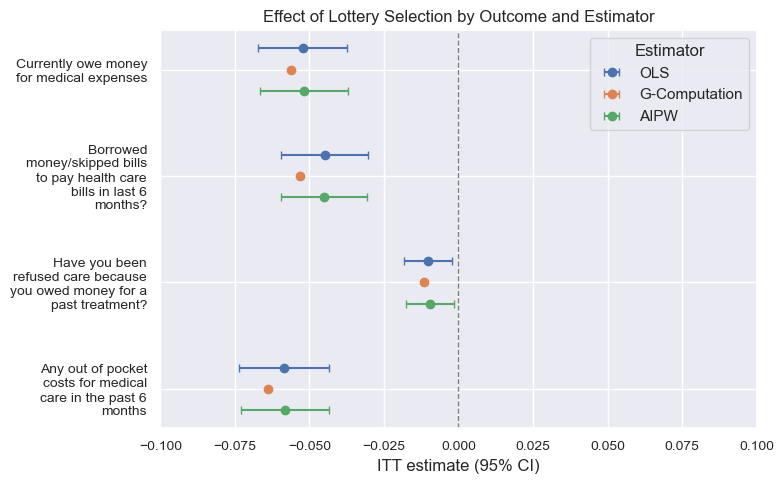

In [70]:
# Lets plot the ITT estimates for all three estimators, across all four outcomes
# Note: To learn how to create a forest-style plot of estimates with confidence intervals for ITT
  # Claude Fable 5. Based on the response to prompt: "How can I create a plot that shows the ITT estimate and CI for each estimator, across all four outcomes."
itt_rows = causal_summary[causal_summary["Estimand"] == "ITT"]
estimators = ["OLS", "G-Computation", "AIPW"]
# Add small vertical offsets so the three estimators being displays dont overlap
offsets = {"OLS": -0.2, "G-Computation": 0, "AIPW": 0.2}

fig, ax = plt.subplots(figsize = (8, 5))
# For each estimator, plot the estimate and its 95% CI (note: g-computation does not have a 95% CI, so only plot the point)
for est in estimators:
    sub = itt_rows[itt_rows["Estimator"] == est]
    ypos = np.arange(len(outcomes)) + offsets[est]
    ax.errorbar(sub["Estimate"], ypos, xerr = 1.96 * sub["SE"].fillna(0), fmt = "o", capsize = 3, label = est)
# Add a reference line at 0 (value if no effect)
ax.axvline(0, linestyle = "--", color = "grey", linewidth = 1.0)
ax.set_yticks(range(len(outcomes)))
# Use the readable labels (instead of the variable names) and use textwrap so they fit
ax.set_yticklabels([textwrap.fill(labels[y], width = 20) for y in outcomes], fontsize = 10)
ax.tick_params(axis = "x", labelsize = 10)
# Invert y axis so the primary outcome is on top
ax.invert_yaxis()
# Center the plot around 0, so the direction of the effect is more clear
ax.set_xlim(-0.1, 0.1)
ax.set_xlabel("ITT estimate (95% CI)")
ax.set_title("Effect of Lottery Selection by Outcome and Estimator")
ax.legend(title = "Estimator")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/ITT.png")
plt.show()

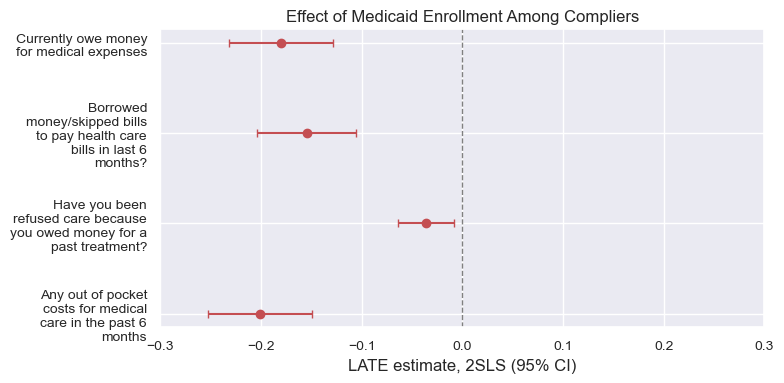

In [71]:
# Now, lets plot the LATE estimates across all four outcomes
# Note: To learn how to create a forest-style plot of estimates with confidence intervals for LATE
  # Claude Fable 5. Based on the response to prompt: "How can I create a plot that shows the LATE estimate and CI for all four outcomes."
late_rows = causal_summary[causal_summary["Estimand"] == "LATE"]

fig, ax = plt.subplots(figsize = (8, 4))
# One estimator, so one point per outcome
ax.errorbar(late_rows["Estimate"], range(len(outcomes)), xerr = 1.96 * late_rows["SE"], fmt = "o", capsize = 3,  color = "C3")
# Add a reference line at 0 (value if no effect)
ax.axvline(0, linestyle = "--", color = "grey", linewidth = 1.0)
ax.set_yticks(range(len(outcomes)))
# Use the outcome labels and wrap them, for readability
ax.set_yticklabels([textwrap.fill(labels[y], width = 20) for y in outcomes], fontsize = 10)
ax.tick_params(axis = "x", labelsize = 10)
# Invert y axis so the primary outcome is on top
ax.invert_yaxis()
# Center the plot around 0, so the direction of the effect is more clear
ax.set_xlim(-0.3, 0.3)
ax.set_xlabel("LATE estimate, 2SLS (95% CI)")
ax.set_title("Effect of Medicaid Enrollment Among Compliers")
plt.tight_layout()
fig.savefig(f"{OUTPUT}/LATE.png")


Across all four outcomes, the three ITT estimators agree: OLS and AIPW are identical to three decimals and g-computation sits within one standard error. The ITT plot shows this directly, with the three points for each outcome overlapping and every confidence interval excluding zero. The LATE plot shows the same ordering of outcomes at roughly 3-4 times the scale.

This shows that the choice between OLS, g-computation, and AIPW does not affect the answer, and the value of the doubly robust estimator is as a check, not a correction. Moving forward, the per-person AIPW scores will be used as inputs for the policy simulation.

## 8. Heterogeneity

---

This section includes:

- 8.1. Causal Forest
- 8.2. CATE Distribution
- 8.3. Calibration Test & GATES
- 8.4. Subgroups Analysis: Age Group, Sex, Language, Prior SNAP/TANF
- 8.5. Forest Feature Importance
- 8.6. Summary of Causal Forest & Subgroup Analysis

### 8.1. Causal Forest

In [72]:

# Design variables (hh_size, wave) are handled by the residualization below, not by the forest, so lets drop them
X_het = X_causal.drop(columns = [c for c in X_causal.columns if c.startswith("hh_size_") or c.startswith("wave_")])

# 
t_res = t_c - e_c
mu0_p, mu1_p, _ = mu[outcome]
y_c = y_fit.to_numpy(dtype = float)
y_res = y_c - (e_c * mu1_p + (1 - e_c) * mu0_p)

cate = np.full(len(y_c), np.nan)
cate_se = np.full(len(y_c), np.nan)
forest_models = []
for train, test in folds:

    cf_fold = CausalForest(
        n_estimators = 1000,
        min_samples_leaf = 50,
        max_depth = None,
        max_samples = 0.5, 
        honest = True,
        inference = True,
        random_state = SEED,
        n_jobs = -1
    )
    cf_fold.fit(X_het.iloc[train], t_res[train], y_res[train], sample_weight = w_c[train])

    pred, lb, ub = cf_fold.predict(X_het.iloc[test], interval = True, alpha = 0.05)
    cate[test] = pred.ravel()
    cate_se[test] = (ub.ravel() - lb.ravel()) / (2 * 1.96)
    forest_models.append(cf_fold)

print(f"Mean CATE: {np.average(cate, weights = w_c):.4f}")
print(f"CATE SD: {cate.std():.4f}, range {cate.min():.4f} to {cate.max():.4f}")

Mean CATE: -0.0531
CATE SD: 0.0316, range -0.1840 to 0.0538


### 8.2. CATE Distribution

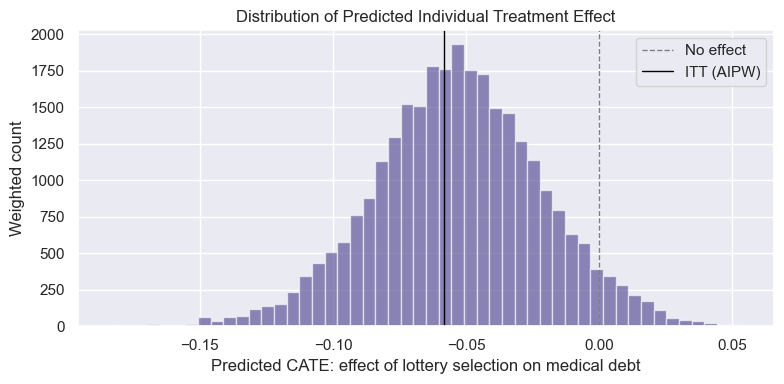

Share with CATE < 0: 0.952


In [76]:
fix, ax = plt.subplots(figsize = (8, 4))
ax.hist(cate, bins = 50, color = "darkslateblue", alpha = 0.6, weights = w_c)
ax.axvline(0, linestyle = "--", color = "grey", linewidth = 1.0, label = "No effect")
ax.axvline(aipw.loc[loop_outcome, "AIPW"], color = "black", linewidth = 1.0, label = "ITT (AIPW)")
ax.set_xlabel("Predicted CATE: effect of lottery selection on medical debt")
ax.set_ylabel("Weighted count")
ax.set_title("Distribution of Predicted Individual Treatment Effect")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Share with CATE < 0: {np.average(cate < 0, weights = w_c):.3f}")

### 8.3. Calibration Test & GATES

In [77]:
cate_mean = np.average(cate, weights = w_c)
cal_X = pd.DataFrame({"mean_cate": cate_mean, "cate_dev": cate - cate_mean})
cal_fit = sm.WLS(psi_primary, cal_X, weights = w_c).fit(cov_type = "cluster", cov_kwds = {"groups": groups_fit.to_numpy()})
print(cal_fit.summary().tables[1])

quintile = pd.Series(pd.qcut(cate, 5, labels = ["Q1 (most benefit)", "Q2", "Q3", "Q4", "Q5 (least benefit)"]))
rows = []
for q in quintile.cat.categories:
    m = (quintile == q).to_numpy()
    est, se = clustered_se(psi_primary[m], w_c[m], groups_fit.to_numpy()[m])
    rows.append({
        "Quintile": q,
        "n": m.sum(),
        "Mean Predicted CATE": np.average(cate[m], weights = w_c[m]),
        "ITT (AIPW)": est,
        "SE": se,
        "CI Low": est - 1.96 * se,
        "CI High": est + 1.96 * se
    })

gates = pd.DataFrame(rows).set_index("Quintile")
gates.round(4)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
mean_cate      0.9736      0.142      6.850      0.000       0.695       1.252
cate_dev       0.0064      0.239      0.027      0.978      -0.462       0.475


,n,Mean Predicted CATE,ITT (AIPW),SE,CI Low,CI High
Quintile,,,,,,
Q1 (most benefit),4690,-0.0972,-0.0538,0.0166,-0.0864,-0.0212
Q2,4690,-0.0687,-0.0376,0.0164,-0.0697,-0.0054
Q3,4690,-0.0529,-0.0613,0.0163,-0.0933,-0.0293
Q4,4690,-0.0366,-0.0480,0.0167,-0.0807,-0.0153
Q5 (least benefit),4690,-0.0086,-0.0578,0.0169,-0.0910,-0.0246


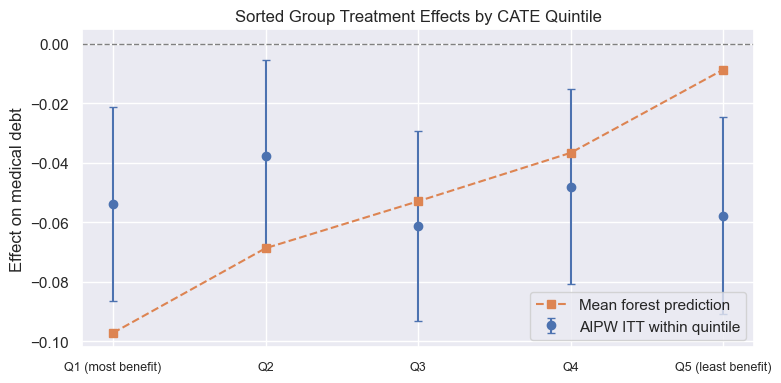

In [78]:
fig, ax = plt.subplots(figsize = (8, 4))
x = np.arange(len(gates))
ax.errorbar(x, gates["ITT (AIPW)"], yerr = 1.96 * gates["SE"], fmt = "o", capsize = 3, color = "C0", label = "AIPW ITT within quintile")
ax.plot(x, gates["Mean Predicted CATE"], marker = "s", linestyle = "--", color = "C1", label = "Mean forest prediction")
ax.axhline(0, linestyle = "--", color = "grey", linewidth = 1.0)
ax.set_xticks(x)
ax.set_xticklabels(gates.index, fontsize = 9)
ax.set_ylabel("Effect on medical debt")
ax.set_title("Sorted Group Treatment Effects by CATE Quintile")
ax.legend()
plt.tight_layout()
plt.show()

### 8.4. Subgroup Analysis: Age Group, Sex, Language, Prior SNAP/TANF

In [81]:
sub_df = df.loc[fit_data]
rows = []
for s in subgroups:
    for level in sorted(sub_df[s].unique()):
        m = (sub_df[s] == level).to_numpy()
        est, se = clustered_se(psi_primary[m], w_c[m], groups_fit.to_numpy()[m])
        rows.append({
            "Subgroup": labels[s],
            "Level": level,
            "n": m.sum(),
            "ITT (AIPW)": est,
            "SE": se,
            "CI Low": est - 1.96 * se,
            "CI High": est + 1.96 * se
        })
subgroup_effects = pd.DataFrame(rows).set_index(["Subgroup", "Level"])
subgroup_effects.round(4)

n  ITT (AIPW)      SE  CI Low  \
Subgroup                      Level                                             
Age group                     18-34          7205     -0.0518  0.0136 -0.0785   
                              35-49          8496     -0.0558  0.0124 -0.0801   
                              50-64          7749     -0.0469  0.0130 -0.0724   
Prior SNAP/TANF participation No SNAP/TANF  10542     -0.0335  0.0115 -0.0560   
                              SNAP/TANF     12908     -0.0667  0.0100 -0.0862   
Sex                           Female        13896     -0.0579  0.0094 -0.0763   
                              Male           9554     -0.0429  0.0118 -0.0660   
Language preference           English       21487     -0.0569  0.0079 -0.0723   
                              Non-English    1963      0.0019  0.0268 -0.0506   

                                            CI High  
Subgroup                      Level                  
Age group                     18-34         -0.0252  
                              35-49         -0.0315  
                              50-64         -0.0213  
Prior SNAP/TANF participation No SNAP/TANF  -0.0110  
                              SNAP/TANF     -0.0471  
Sex                           Female        -0.0395  
                              Male          -0.0198  
Language preference           English       -0.0414  
                              Non-English    0.0544

In [82]:
rows = []
for s in subgroups:
    d = pd.DataFrame({"psi": psi_primary, "w": w_c, "g": groups_fit.to_numpy(), s: sub_df[s].to_numpy()})
    m = smf.wls(f"psi ~ C({s})", data = d, weights = d["w"]).fit(cov_type = "cluster", cov_kwds = {"groups": d["g"]})
    terms = [t for t in m.params.index if t.startswith(f"C({s})")]
    wald = m.wald_test(" = ".join(terms) + " = 0", scalar = True) if len(terms) > 1 else m.wald_test(f"{terms[0]} = 0", scalar = True)
    rows.append({
        "Subgroup": labels[s],
        "Levels": d[s].nunique(),
        "Wald Stat": float(wald.statistic),
        "p": float(wald.pvalue)
    })
subgroup_tests = pd.DataFrame(rows).set_index("Subgroup")
subgroup_tests.round(4)

,Levels,Wald Stat,p
Subgroup,,,
Age group,3,0.2495,0.8827
Prior SNAP/TANF participation,2,4.7890,0.0286
Sex,2,1.0497,0.3056
Language preference,2,4.4384,0.0351


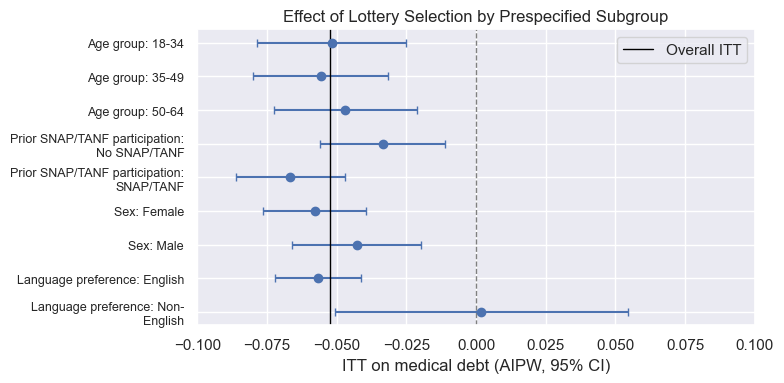

In [83]:
fig, ax = plt.subplots(figsize = (8, 4))
ypos = np.arange(len(subgroup_effects))
ax.errorbar(subgroup_effects["ITT (AIPW)"], ypos, xerr = 1.96 * subgroup_effects["SE"], fmt = "o", capsize = 3, color = "C0")
ax.axvline(itt.loc[outcome, "ITT"], color = "black", linewidth = 1.0, label = "Overall ITT")
ax.axvline(0, linestyle = "--", color = "grey", linewidth = 1.0)
ax.set_yticks(ypos)
ax.set_yticklabels([textwrap.fill(f"{s}: {l}", width = 30) for s, l in subgroup_effects.index], fontsize = 9)
ax.invert_yaxis()
ax.set_xlim(-0.1, 0.1)
ax.set_xlabel("ITT on medical debt (AIPW, 95% CI)")
ax.set_title("Effect of Lottery Selection by Prespecified Subgroup")
ax.legend()
plt.tight_layout()
plt.show()

### 8.5. Forest Feature Importance

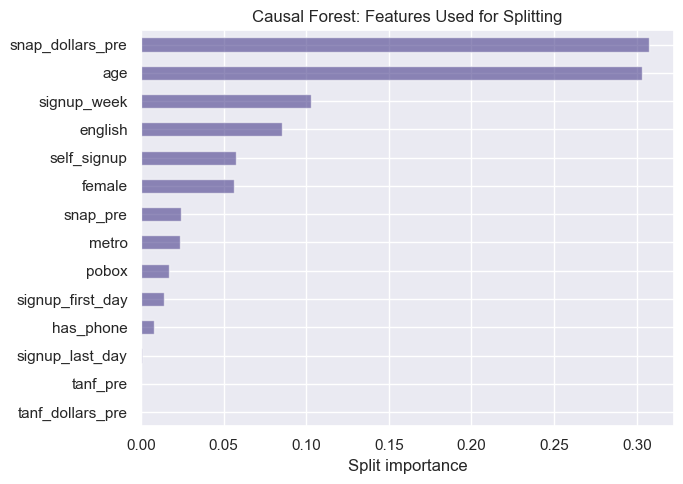

In [85]:
forest_importance = pd.Series(np.mean([f.feature_importances_ for f in forest_models], axis = 0), index = X_het.columns).sort_values(ascending = False)

fig, ax = plt.subplots(figsize = (7, 5))
forest_importance.plot.barh(ax = ax, color = "darkslateblue", alpha = 0.6)
ax.invert_yaxis()
ax.set_xlabel("Split importance")
ax.set_title("Causal Forest: Features Used for Splitting")
plt.tight_layout()
plt.show()

### 8.6. Summary of Causal Forest & Subgroup Analysis

## 9. Policy Simulation

---

This section includes:

- 9.1. Determine Fixed Budget
- 9.2. Allocation Rules: Lottery, Need-Based, Risk-Based, Universal
- 9.3. Doubly Robust Evaluation of Each Rule using AIPW
- 9.4. G-Computation Cross-Check
- 9.5. Household Bootstrap for Uncertainty Estimation
- 9.6. Budget Sweep & Summary 

### 9.1. Determine Fixed Budget

In [96]:
budget = np.average(t_c, weights = w_c)
n_offers = int(round(budget * len(t_c)))
print(f"Budget: {budget: .3f} of the list, {n_offers} offers out of {len(t_c)} respondents")

baseline_debt = np.average(gamma0_primary, weights = w_c)
print(f"Expected medical debt rate with no offers: {baseline_debt:.4f}")

def evaluate_rule(d):
    debt_rate = np.average(d * gamma1_primary + (1 - d) * gamma0_primary, weights = w_c)
    averted, averted_se = clustered_se(d * psi_primary, w_c, groups_fit.to_numpy())
    return debt_rate, averted, averted_se

def allocate(score, n_offers, rng = np.random.default_rng(SEED)):
    order = np.lexsort((rng.random(len(score)), -score))
    d = np.zeros(len(score))
    d[order[:n_offers]] = 1
    return d

Budget:  0.501 of the list, 11747 offers out of 23450 respondents
Expected medical debt rate with no offers: 0.5910


### 9.2. Allocation Rules: Lottery, Need-Based, Risk-Based, Universal

In [98]:
scores = {}

# Random
scores["Lottery"] = np.random.default_rng(SEED).random(len(t_c))

# Need-based
scores["Need-based"] = (df.loc[fit_data, "snap_dollars_pre"] + df.loc[fit_data, "tanf_dollars_pre"]).to_numpy()

risk = np.full(len(t_c), np.nan)
X_risk = X_fit.copy()
X_risk[treatment] = 0
for (train, test), model in zip(folds, fold_models["xgboost"]):
    risk[test] = model.predict_proba(X_risk.iloc[test])[:, 1]
scores["Risk-based"] = risk

scores["Benefit-based"] = -cate
scores["Universal"] = np.ones(len(t_c))

allocations = {name: allocate(s, n_offers) for name, s in scores.items()}
allocations["Universal"] = np.ones(len(t_c))
pd.DataFrame({name: d.sum() for name, d in allocations.items()}, index = ["Offers"]).T

,Offers
Lottery,11747.0
Need-based,11747.0
Risk-based,11747.0
Benefit-based,11747.0
Universal,23450.0


### 9.3. Doubly Robust Evaluation of Each Rule using AIPW

In [99]:
rows = []
for name, d in allocations.items():
    debt_rate, averted, averted_se = evaluate_rule(d)
    rows.append({
        "Rule": name,
        "Offers": int(d.sum()),
        "Expected Debt Rate": debt_rate,
        "Debt Averted": -averted,
        "SE": averted_se,
        "CI Low": -averted - 1.96 * averted_se,
        "CI High": -averted + 1.96 * averted_se
    })

policy_results = pd.DataFrame(rows).set_index("Rule")
policy_results["Gain vs Lottery"] = policy_results["Debt Averted"] - policy_results.loc["Lottery", "Debt Averted"]
policy_results.round(4)

,Offers,Expected Debt Rate,Debt Averted,SE,CI Low,CI High,Gain vs Lottery
Rule,,,,,,,
Lottery,11747,0.5653,0.0257,0.0053,0.0154,0.0360,0.0000
Need-based,11747,0.5590,0.0320,0.0053,0.0217,0.0423,0.0063
Risk-based,11747,0.5545,0.0365,0.0051,0.0265,0.0465,0.0108
Benefit-based,11747,0.5659,0.0252,0.0053,0.0148,0.0355,-0.0005
Universal,23450,0.5393,0.0517,0.0075,0.0369,0.0665,0.0260


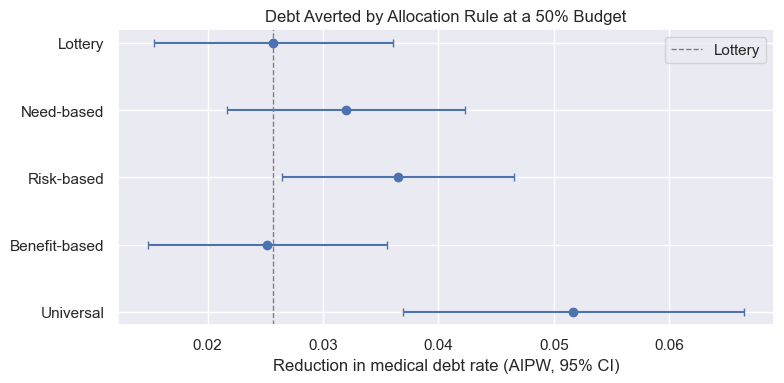

In [100]:
fig, ax = plt.subplots(figsize = (8, 4))
ypos = np.arange(len(policy_results))
ax.errorbar(policy_results["Debt Averted"], ypos, xerr = 1.96 * policy_results["SE"], fmt = "o", capsize = 3, color = "C0")
ax.axvline(policy_results.loc["Lottery", "Debt Averted"], linestyle = "--", color = "grey", linewidth = 1.0, label = "Lottery")
ax.set_yticks(ypos)
ax.set_yticklabels(policy_results.index)
ax.invert_yaxis()
ax.set_xlabel("Reduction in medical debt rate (AIPW, 95% CI)")
ax.set_title(f"Debt Averted by Allocation Rule at a {budget:.0%} Budget")
ax.legend()
plt.tight_layout()
plt.show()

### 9.4. G-Computation Cross-Check

In [103]:
tau_gcomp = mu1_p - mu0_p
policy_results["Debt Averted (g-comp)"] = [-np.average(d * tau_gcomp, weights = w_c) for d in allocations.values()]
policy_results[["Debt Averted", "Debt Averted (g-comp)"]].round(4)

,Debt Averted,Debt Averted (g-comp)
Rule,,
Lottery,0.0257,0.0284
Need-based,0.0320,0.0350
Risk-based,0.0365,0.0389
Benefit-based,0.0252,0.0404
Universal,0.0517,0.0561


### 9.5. Household Bootstrap for Uncertainty Estimation

In [108]:
hh = groups_fit.to_numpy()
contribution = pd.DataFrame({name: -d * psi_primary * w_c for name, d in allocations.items()})
contribution["Lottery"] = -budget * psi_primary * w_c
contribution["w"] = w_c
contribution["hh"] = hh
hh_sums = contribution.groupby("hh").sum()

rng = np.random.default_rng(SEED)
n_boot = 1000
rule_names = list(allocations.keys())
boot = np.zeros((n_boot, len(rule_names)))
for b in range(n_boot):
    idx = rng.integers(0, len(hh_sums), size = len(hh_sums))
    s = hh_sums.iloc[idx].sum()
    averted = s[rule_names] / s["w"]
    boot[b] = averted - averted["Lottery"]

gain = pd.DataFrame({
    "Gain vs Lottery": policy_results.loc[rule_names, "Gain vs Lottery"],
    "Boot SE": boot.std(axis = 0),
    "CI Low": np.percentile(boot, 2.5, axis = 0),
    "CI High": np.percentile(boot, 97.5, axis = 0)
}, index = rule_names)

gain.round(4)

,Gain vs Lottery,Boot SE,CI Low,CI High
Lottery,0.0000,0.0000,0.0000,0.0000
Need-based,0.0063,0.0037,-0.0007,0.0136
Risk-based,0.0108,0.0038,0.0035,0.0174
Benefit-based,-0.0005,0.0037,-0.0080,0.0061
Universal,0.0260,0.0038,0.0186,0.0335


### 9.6. Budget Sweep & Summary 

In [114]:
budgets = np.arange(0.1, 1.01, 0.1)
rows = []
for b in budgets:
    k = int(round(b * len(t_c)))
    for name, s in scores.items():
        if name == "Universal":
            continue
        d = allocate(s, k)
        _, averted, _ = evaluate_rule(d)
        rows.append({
            "Budget": b,
            "Rule": name,
            "Debt Averted": -averted
        })
    rows.append({
        "Budget": b,
        "Rule": "Lottery (expected)",
        "Debt Averted": -b * np.average(psi_primary, weights = w_c)
    })

sweep = pd.DataFrame(rows)
sweep

,Budget,Rule,Debt Averted
0,0.1,Lottery,0.002570
1,0.1,Need-based,0.009306
2,0.1,Risk-based,0.004748
3,0.1,Benefit-based,0.006505
4,0.1,Lottery (expected),0.005170
5,0.2,Lottery,0.011544
6,0.2,Need-based,0.014743
7,0.2,Risk-based,0.013703
8,0.2,Benefit-based,0.011006
9,0.2,Lottery (expected),0.010341


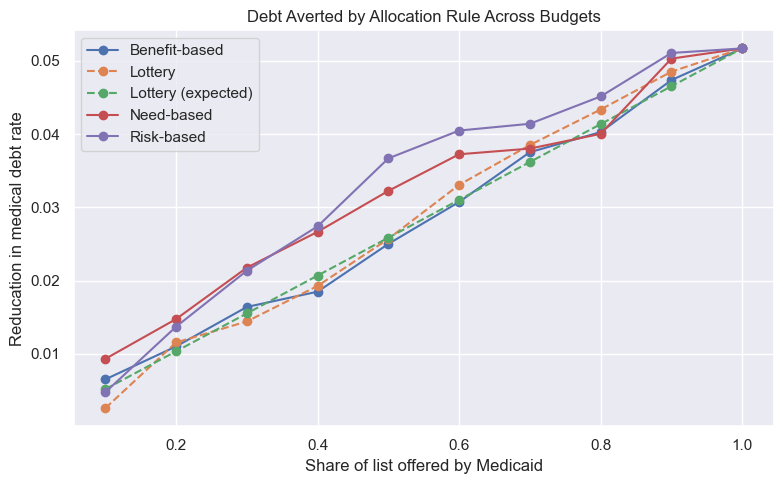

In [115]:
fig, ax = plt.subplots(figsize = (8, 5))
for name, g in sweep.groupby("Rule"):
    style = "--" if name.startswith("Lottery") else "-"
    ax.plot(g["Budget"], g["Debt Averted"], marker = "o", linestyle = style, label = name)
ax.set_xlabel("Share of list offered by Medicaid")
ax.set_ylabel("Reducation in medical debt rate")
ax.set_title("Debt Averted by Allocation Rule Across Budgets")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Summary & Limitations
---

This selection includes:

  - 10.1. Results
  - 10.2. Limitations
  - 10.3. Conclusions

## AI Use Statement
---

Generative AI (Claude) was used as a coding, learning, and editing assistant for the following:

- Python syntax and package questions, such as reading Stata with pyreadstat, household-grouped cross-validation with GroupKFold, and fitting 2SLS with linearmodels.
- Brainstorming, implementing, and understanding supervised machine learning models (logistic regression, random forest, XGBoost), including hyperparameter tuning, threshold selection, calibration, variable importance (permutation importance, SHAP), and interpreting results.
- Brainstorming, implementing, and understanding causal inference methods (ITT via OLS, LATE via 2SLS, g-computation, AIPW), including design-based propensity score, survey weighting, household-clusters, and interpreting results.
- Brainstorming and editing notebook and README structure / contents, and learning reproducibility and automation best practices.

I verified and reviewed all work. I take full responsibility for the accuracy and legitimacy of all work submitted.